In [ ]:
import pandas as pd
import numpy as np
import os
import re

# Paths to 7 datasets
files = {
    "enrolment_school_district": "/content/enrolment_school_district.csv",
    "gdp_district_real_supply": "/content/gdp_district_real_supply.csv",
    "hh_access_amenities": "/content/hh_access_amenities.csv",
    "hh_poverty_district": "/content/hh_poverty_district.csv",
    "hies_district": "/content/hies_district.csv",
    "lfs_district": "/content/lfs_district.csv",
    "schools_district": "/content/schools_district.csv",
}

def summarize_dataset(name, path):
    if not os.path.exists(path):
        print(f"\n{name}: File not found at {path}")
        return
    try:
        df = pd.read_csv(path)
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding="latin-1")

    print(f"\n===== {name} =====")
    print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
    print("\nColumns & types:")
    print(df.dtypes)

    print("\nMissing values (top 5):")
    print(df.isna().sum().sort_values(ascending=False).head())

    # If a date column exists, show min/max year
    if "date" in df.columns:
        df["date"] = pd.to_datetime(df["date"], errors="coerce")
        if df["date"].notna().any():
            years = df["date"].dt.year.dropna().unique()
            print("\nYear range:", years.min(), "to", years.max())

    print("\nPreview:")
    display(df.head())

# Run summaries
for name, path in files.items():
    summarize_dataset(name, path)


===== enrolment_school_district =====
Shape: 8465 rows × 6 columns

Columns & types:
state              object
district           object
education stage    object
sex                object
date               object
students            int64
dtype: object

Missing values (top 5):
state              0
district           0
education stage    0
sex                0
date               0
dtype: int64

Year range: 2017 to 2022

Preview:


,state,district,education stage,sex,date,students
0,Malaysia,All Districts,primary,both,2017-01-01,2689810
1,Malaysia,All Districts,primary,both,2018-01-01,2694779
2,Malaysia,All Districts,primary,both,2019-01-01,2729704
3,Malaysia,All Districts,primary,both,2020-01-01,2741995
4,Malaysia,All Districts,primary,both,2021-01-01,2766202



===== gdp_district_real_supply =====
Shape: 10626 rows × 6 columns

Columns & types:
series       object
state        object
district     object
date         object
sector       object
value       float64
dtype: object

Missing values (top 5):
value       1238
series         0
state          0
district       0
date           0
dtype: int64

Year range: 2015 to 2020

Preview:


,series,state,district,date,sector,value
0,abs,Johor,Batu Pahat,2015-01-01,p0,11605.5017
1,abs,Johor,Batu Pahat,2015-01-01,p1,2177.2570
2,abs,Johor,Batu Pahat,2015-01-01,p2,13.0113
3,abs,Johor,Batu Pahat,2015-01-01,p3,3255.7651
4,abs,Johor,Batu Pahat,2015-01-01,p4,109.0029



===== hh_access_amenities =====
Shape: 496 rows × 6 columns

Columns & types:
date            object
state           object
district        object
piped_water    float64
sanitation     float64
electricity    float64
dtype: object

Missing values (top 5):
piped_water    1
date           0
state          0
district       0
sanitation     0
dtype: int64

Year range: 2016 to 2022

Preview:


,date,state,district,piped_water,sanitation,electricity
0,2016-01-01,Johor,All Districts,99.9,99.99,100.0
1,2019-01-01,Johor,All Districts,99.9,99.90,100.0
2,2022-01-01,Johor,All Districts,99.6,100.00,99.6
3,2016-01-01,Johor,Batu Pahat,99.9,100.00,100.0
4,2019-01-01,Johor,Batu Pahat,100.0,100.00,100.0


... (4 outputs left out)


===== lfs_district =====
Shape: 560 rows × 10 columns

Columns & types:
state             object
district          object
date              object
lf               float64
lf_employed      float64
lf_unemployed    float64
lf_outside       float64
p_rate           float64
u_rate           float64
ep_ratio         float64
dtype: object

Missing values (top 5):
state          0
district       0
date           0
lf             0
lf_employed    0
dtype: int64

Year range: 2019 to 2022

Preview:


,state,district,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio
0,Johor,Batu Pahat,2019-01-01,213.6,209.8,3.7,90.4,70.3,1.7,69.035867
1,Johor,Batu Pahat,2020-01-01,219.1,214.4,4.7,92.2,70.4,2.1,68.850353
2,Johor,Batu Pahat,2021-01-01,216.0,211.0,5.0,97.1,69.0,2.3,67.390610
3,Johor,Batu Pahat,2022-01-01,220.8,216.8,4.0,94.6,70.0,1.8,68.738110
4,Johor,Johor Bahru,2019-01-01,792.4,767.8,24.6,293.7,73.0,3.1,70.693306



===== schools_district =====
Shape: 2993 rows × 6 columns

Columns & types:
state                object
district             object
education stage      object
school type          object
date                 object
number of schools     int64
dtype: object

Missing values (top 5):
state              0
district           0
education stage    0
school type        0
date               0
dtype: int64

Year range: 2017 to 2022

Preview:


,state,district,education stage,school type,date,number of schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773
3,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,7780
4,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,7780


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# ===== CONFIG =====
BASE_DIR = Path("/content")

FILES = {
    "poverty":  BASE_DIR / "hh_poverty_district.csv",
    "hies":     BASE_DIR / "hies_district.csv",
    "lfs":      BASE_DIR / "lfs_district.csv",
    "amen":     BASE_DIR / "hh_access_amenities.csv",
    "schools":  BASE_DIR / "schools_district.csv",
    "enrol":    BASE_DIR / "enrolment_school_district.csv",
    "gdp":      BASE_DIR / "gdp_district_real_supply.csv",
}
# GDP 2022 is missing, switch this to 2020 to keep GDP (lagged proxy)
GDP_YEAR = 2020
OUT = BASE_DIR / "unified_district_socio_2022.csv"

# Minimal mapping ONLY for the conflicts reported
NAME_FIX = {
    # exact conflicts seen in summary:
    "Larut Dan Matang": "Larut dan Matang",
    "Hulu Langat": "Ulu Langat",
    "Hulu Selangor": "Ulu Selangor",
    # Harmonization for old labels:
    "Manjung (Dinding)": "Manjung",
    "Kuala Lipis": "Lipis",
    # combined label cannot be split reliably; we will drop it
    "Larut Matang & Selama": None,   # mark for drop
    "All Districts": None,
    "Supra": None,
}

DROP_LABELS = set([k for k, v in NAME_FIX.items() if v is None])

# ---------- helpers ----------
def pick_col(df, candidates):
    lc = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lc:
            return lc[cand.lower()]
    # substring fallback
    for c in df.columns:
        for cand in candidates:
            if cand.lower() in c.lower():
                return c
    return None

def filter_to_year(df, year=2022):
    # find a year/date column
    cand_cols = [c for c in df.columns if any(k in c.lower() for k in ["year","date","tarikh","period","bulan","month"])]
    for col in cand_cols:
        s = df[col]
        # numeric year
        if pd.api.types.is_numeric_dtype(s):
            mask = s.astype("Int64") == year
            if mask.any():
                return df.loc[mask].copy()
        # parseable dates (e.g., 01/01/2022)
        dt = pd.to_datetime(s, errors="ignore", dayfirst=False)
        if pd.api.types.is_datetime64_any_dtype(dt):
            mask = dt.dt.year == year
            if mask.any():
                out = df.loc[mask].copy()
                # store normalized date if needed
                out[col] = dt.loc[mask]
                return out
        # sometimes strings that parse on second try
        dt = pd.to_datetime(s.astype(str), errors="coerce", dayfirst=False)
        if dt.notna().any():
            mask = dt.dt.year == year
            if mask.any():
                out = df.loc[mask].copy()
                out[col] = dt.loc[mask]
                return out
    return df.copy()  # if no suitable column, leave unchanged

def clean_labels(df, dist_col="district"):
    # drop junk rows, map minimal fixes
    if dist_col not in df.columns:
        raise ValueError(f"Expected '{dist_col}' column.")
    df = df.copy()
    # Drop 'All Districts', 'Supra', 'Larut Matang & Selama'
    if DROP_LABELS:
        df = df[~df[dist_col].isin(DROP_LABELS)].copy()
    # Apply minimal renames
    df[dist_col] = df[dist_col].replace({k: v for k, v in NAME_FIX.items() if v is not None})
    return df

def load_base(path, label):
    df = pd.read_csv(path)
    dist_col = pick_col(df, ["district","daerah","district_name","daerah_name"])
    if dist_col != "district":
        df = df.rename(columns={dist_col: "district"})
    df = filter_to_year(df, 2022)
    df = clean_labels(df, "district")
    print(f"\n=== {label.upper()} ===")
    print("Rows after 2022 filter & label clean:", len(df))
    print("Columns:", list(df.columns))
    print("Unique districts:", df["district"].nunique())
    return df

def normalise_stage(s: str) -> str:
    """
    Map any variant of stage labels to {primary, secondary, tertiary}.
    Handles Malay labels too.
    """
    if not isinstance(s, str):
        return None
    st = s.strip().lower()

    # primary
    if any(k in st for k in ["primary", "rendah", "sekolah rendah", "sekolahrendah"]):
        return "primary"

    # secondary
    if any(k in st for k in ["secondary", "menengah", "sekolah menengah", "sekolahmenengah"]):
        return "secondary"

    # tertiary / post-secondary (IPTA, IPTS, college, university)
    if any(k in st for k in ["tertiary", "post", "ipt", "college", "universit"]):
        return "tertiary"

    # if still unknown, return None (will be excluded)
    return None

# ---------- load & pre-aggregate ----------
poverty = load_base(FILES["poverty"], "poverty")

# HIES is 1 row/district → keep as-is but ensure unique
hies = load_base(FILES["hies"], "hies")
hies = (hies
        .drop_duplicates(subset=["district"], keep="first"))

# LFS may already be 1 row/district; if not, aggregate key rates by mean and counts by sum
lfs = load_base(FILES["lfs"], "lfs")
if lfs["district"].duplicated().any():
    agg = {}
    for c in lfs.columns:
        if c in ["district","state","date"]:
            continue
        if any(k in c.lower() for k in ["rate","ratio","rate)"]):
            agg[c] = "mean"
        else:
            agg[c] = "sum"
    lfs = lfs.groupby("district", as_index=False).agg(agg)

# Amenities (1 row/district expected; drop any aggregates)
amen = load_base(FILES["amen"], "amen")
amen = amen.drop_duplicates(subset=["district"], keep="first")

# Schools: long by education stage/school type → aggregate to district totals
schools = load_base(FILES["schools"], "schools")

stage_col_sch = pick_col(schools, ["education stage","stage","edu_stage"])
num_col_sch   = pick_col(schools, ["number of schools","num_schools","schools"])
if stage_col_sch is None or num_col_sch is None:
    raise ValueError("Cannot find stage or number-of-schools columns in SCHOOLS")

# Normalise stage labels
schools["stage_norm"] = schools[stage_col_sch].map(normalise_stage)

schools_agg = (
    schools
      .dropna(subset=["stage_norm"])
      .groupby(["district", "stage_norm"], as_index=False)[num_col_sch]
      .sum()
      .pivot(index="district", columns="stage_norm", values=num_col_sch)
      .rename(columns={
          "primary":   "schools_primary",
          "secondary": "schools_secondary",
          "tertiary":  "schools_tertiary"
      })
      .reset_index()
)

# Enrol: long by stage & sex → aggregate to district totals
enrol = load_base(FILES["enrol"], "enrol")

stage_col_en  = pick_col(enrol, ["education stage","stage","edu_stage"])
sex_col_en    = pick_col(enrol, ["sex","gender"])
stud_col_en   = pick_col(enrol, ["students","enrol","enrolment"])
if stage_col_en is None or sex_col_en is None or stud_col_en is None:
    raise ValueError("Cannot find stage, sex or students columns in ENROL")

# Keep sex == 'both' to avoid double counting
enrol = enrol[enrol[sex_col_en].astype(str).str.lower().eq("both")].copy()

# Normalise stage labels
enrol["stage_norm"] = enrol[stage_col_en].map(normalise_stage)

enrol_agg = (
    enrol
      .dropna(subset=["stage_norm"])
      .groupby(["district", "stage_norm"], as_index=False)[stud_col_en]
      .sum()
      .pivot(index="district", columns="stage_norm", values=stud_col_en)
      .rename(columns={
          "primary":   "students_primary",
          "secondary": "students_secondary",
          "post_secondary":  "students_tertiary"
      })
      .reset_index()
)

# GDP: wide vs long. My file is long by sector. Keep target year (2022 or 2020 fallback) and pivot.
gdp_raw = pd.read_csv(FILES["gdp"])
# Clean labels minimally and filter year
dist_col = pick_col(gdp_raw, ["district","daerah","district_name","daerah_name"])
if dist_col != "district":
    gdp_raw = gdp_raw.rename(columns={dist_col: "district"})
gdp_raw = clean_labels(gdp_raw, "district")

date_col = pick_col(gdp_raw, ["year","date","period"])
if GDP_YEAR is not None:
    gdp_f = filter_to_year(gdp_raw, GDP_YEAR)
    gdp_f = gdp_f[gdp_f["series"] == "abs"]
    if date_col in gdp_f.columns and len(gdp_f):
        pass
    else:
        print(f"⚠️ GDP for {GDP_YEAR} not found. Dropping GDP. "
              f"(Set GDP_YEAR=2020 to use lagged GDP instead.)")
        gdp_f = None
else:
    gdp_f = None

if gdp_f is not None and len(gdp_f):
    sec_col = pick_col(gdp_f, ["sector","industry","kategori"])
    val_col = pick_col(gdp_f, ["value","gdp","amount","nilai"])
    # Drop non-district junk if any remains
    gdp_f = gdp_f.dropna(subset=["district"])
    gdp_piv = (gdp_f
               .pivot_table(index="district", columns=sec_col, values=val_col, aggfunc="sum")
               .reset_index())
    gdp_piv.columns = ["district"] + [f"gdp_{str(c).strip().lower().replace(' ','_')}_{GDP_YEAR}" for c in gdp_piv.columns[1:]]
else:
    gdp_piv = None

# ---------- coverage checks vs poverty ----------
poverty_set = set(poverty["district"])
def check_missing(name, df):
    s = set(df["district"])
    miss_here = sorted(list(poverty_set - s))
    extra_there = sorted(list(s - poverty_set))
    if miss_here:
        print(f"⚠️ In {name}: missing {len(miss_here)} districts vs POVERTY (examples): {miss_here[:8]}")
    if extra_there:
        print(f"⚠️ In {name}: extra {len(extra_there)} districts not in POVERTY (examples): {extra_there[:8]}")

for nm, df in [("HIES", hies), ("LFS", lfs), ("AMEN", amen), ("SCHOOLS", schools_agg), ("ENROL", enrol_agg)]:
    check_missing(nm, df)
if gdp_piv is not None:
    check_missing("GDP", gdp_piv)

# ---------- MERGE (left on poverty, one row/district) ----------
merged = poverty.copy()
merged = merged.merge(hies,         on="district", how="left", suffixes=("", "_hies"))
merged = merged.merge(lfs,          on="district", how="left", suffixes=("", "_lfs"))
merged = merged.merge(amen,         on="district", how="left", suffixes=("", "_amen"))
merged = merged.merge(schools_agg,  on="district", how="left")
merged = merged.merge(enrol_agg,    on="district", how="left")
if gdp_piv is not None:
    merged = merged.merge(gdp_piv,  on="district", how="left")

# Sanity: should be same row count as poverty
print("\n✅ Final merged rows (should be 160):", len(merged))
print("Columns:", len(merged.columns))
print(merged.head(3))

merged.to_csv(OUT, index=False, encoding="utf-8-sig")
print("Saved:", OUT)


=== POVERTY ===
Rows after 2022 filter & label clean: 160
Columns: ['state', 'district', 'date', 'poverty_absolute (%)', 'poverty_relative (%)']
Unique districts: 160

=== HIES ===
Rows after 2022 filter & label clean: 160
Columns: ['date', 'state', 'district', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty']
Unique districts: 160

=== LFS ===
Rows after 2022 filter & label clean: 140
Columns: ['state', 'district', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio']
Unique districts: 140

=== AMEN ===
Rows after 2022 filter & label clean: 158
Columns: ['date', 'state', 'district', 'piped_water', 'sanitation', 'electricity']
Unique districts: 158

=== SCHOOLS ===
Rows after 2022 filter & label clean: 449
Columns: ['state', 'district', 'education stage', 'school type', 'date', 'number of schools']
Unique districts: 151

=== ENROL ===
Rows after 2022 filter & label clean: 1341
Columns: ['state', 'district', 'education stage', 

/tmp/ipython-input-3063626159.py:62: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  dt = pd.to_datetime(s, errors="ignore", dayfirst=False)
/tmp/ipython-input-3063626159.py:62: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  dt = pd.to_datetime(s, errors="ignore", dayfirst=False)
/tmp/ipython-input-3063626159.py:62: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  dt = pd.to_datetime(s, errors="ignore", dayfirst=False)
/tmp/ipython-input-3063626159.py:62: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  dt = pd.to_datetime(s, error

In [ ]:
# Load merged file
df = pd.read_csv("/content/unified_district_socio_2022.csv")

# --- 1) Make % columns numeric (strip % if present) ---
pct_like = [c for c in df.columns if c.endswith("(%)") or "percent" in c.lower() or "rate" in c.lower()]
for c in pct_like:
    df[c] = (df[c].astype(str)
                   .str.replace("%","", regex=False)
                   .str.replace(",","", regex=False)
                   .replace({"nan": np.nan, "NaN": np.nan, "": np.nan})
                   .astype(float))

# --- 2) Tidy GDP column names ---
# Map p0-p5 to readable labels
gdp_map = {
    "gdp_p0_2020": "gdp_total",
    "gdp_p1_2020": "gdp_agriculture",
    "gdp_p2_2020": "gdp_mining",
    "gdp_p3_2020": "gdp_manufacturing",
    "gdp_p4_2020": "gdp_construction",
    "gdp_p5_2020": "gdp_services",
}
rename_these = {k: v for k, v in gdp_map.items() if k in df.columns}
df = df.rename(columns=rename_these)

# --- 3) Keep a single canonical date (2022-01-01) and drop the rest of date dupes ---
date_cols = [c for c in df.columns if c.startswith("date")]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")
# pick base date column (first)
base_date_col = "date" if "date" in df.columns else (date_cols[0] if date_cols else None)
if base_date_col:
    keep = df[[base_date_col]].copy()
    df = df.drop(columns=[c for c in date_cols if c != base_date_col])
    df = df.rename(columns={base_date_col: "date"})

# --- 4) Keep only one canonical 'state' column, drop duplicates from merges ---
state_cols = [c for c in df.columns if c.lower().startswith("state")]
if state_cols:
    # choose the first non-empty one as canonical
    main_state = state_cols[0]
    df = df.rename(columns={main_state: "state"})
    # drop the rest
    drop_states = [c for c in state_cols if c != main_state]
    if drop_states:
        df = df.drop(columns=drop_states)

# Save
df.to_csv("/content/unified_district_socio_2022_clean.csv", index=False, encoding="utf-8-sig")

print("Saved:")
print(" - /content/unified_district_socio_2022_clean.csv")

Saved:
 - /content/unified_district_socio_2022_clean.csv


In [ ]:
# Check for availability of different district name

import pandas as pd
import geopandas as gpd

# Load CSV
df = pd.read_csv("unified_district_socio_2022_clean.csv")

# Load ADM2
adm2 = gpd.read_file("geoBoundaries-MYS-ADM2.geojson")

# Find the right name column
if "district" not in adm2.columns:
    if "shapeName" in adm2.columns:
        adm2 = adm2.rename(columns={"shapeName":"district"})
    else:
        # fallback: first non-geometry column
        non_geom = [c for c in adm2.columns if c != adm2.geometry.name]
        adm2 = adm2.rename(columns={non_geom[0]:"district"})

# Compare district names
csv_districts = set(df["district"].astype(str).unique())
adm2_districts = set(adm2["district"].astype(str).unique())

missing_in_adm2 = csv_districts - adm2_districts
extra_in_adm2   = adm2_districts - csv_districts

print("Districts in CSV but not in ADM2:", missing_in_adm2)
print("Districts in ADM2 but not in CSV:", extra_in_adm2)

Districts in CSV but not in ADM2: {'W.P. Kuala Lumpur', 'Kulai', 'W.P. Labuan', 'W.P. Putrajaya', 'Nabawan', 'Tangkak'}
Districts in ADM2 but not in CSV: {'Kulaijaya', 'Nabawan / Persiangan', 'Labuan', 'Kuala Lumpur', 'Ledang'}


In [ ]:
from pathlib import Path
!pip install geopandas rasterio rasterstats
import rasterio

BASE = Path("/content")
WORLDPOP = BASE / "mys_ppp_2020_UNadj.tif"

print("WorldPop exists? ->", WORLDPOP.exists())
if WORLDPOP.exists():
    try:
        with rasterio.open(WORLDPOP) as src:
            print("Driver:", src.driver, "| Dtype:", src.dtypes[0])
            print("CRS:", src.crs)
            print("Shape:", src.width, "x", src.height)
            print("Bounds:", src.bounds)
            print("Nodata:", src.nodata)
    except Exception as e:
        print("FAILED to open WorldPop:", e)
else:
    # list folder to see what’s actually there
    import os
    print("Files under BASE:")
    for p in sorted(BASE.glob("*")):
        print(" -", p.name)

WorldPop exists? -> True
Driver: GTiff | Dtype: float32
CRS: EPSG:4326
Shape: 23556 x 7831
Bounds: BoundingBox(left=99.640416283, bottom=0.8554168650000005, right=119.270416204, top=7.381250172)
Nodata: -99999.0


In [ ]:
# --- Urbanization features: ADM2 + WorldPop 2020 + GHSL BUILT-S 2020 + GHS-SMOD 2020 ---
# Outputs: unified_district_socio_2022_urban.csv
!pip install geopandas rasterio rasterstats
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterstats import zonal_stats
from rasterio.warp import reproject, Resampling

# ==================== CONFIG ====================
# Set to folder containing the files
BASE = Path("/content")

SOCIO_CSV   = BASE / "unified_district_socio_2022_clean.csv"
ADM2_PATH = BASE / "geoBoundaries-MYS-ADM2.geojson"

# WorldPop 2020 population (100 m, UN-adjusted Malaysia)
WORLDPOP  = BASE / "mys_ppp_2020_UNadj.tif"

# GHSL BUILT-S (2020) tiles for Malaysia (Mollweide ESRI:54009, 100 m)
BUILT_W   = BASE / "GHS_BUILT_S_E2020_GLOBE_R2023A_54009_100_V1_0_R9_C29.tif"
BUILT_E   = BASE / "GHS_BUILT_S_E2020_GLOBE_R2023A_54009_100_V1_0_R9_C30.tif"

# GHS-SMOD (2020) tiles for Malaysia (Mollweide ESRI:54009, 1 km)
SMOD_W    = BASE / "GHS_SMOD_E2020_GLOBE_R2023A_54009_1000_V2_0_R9_C29.tif"
SMOD_E    = BASE / "GHS_SMOD_E2020_GLOBE_R2023A_54009_1000_V2_0_R9_C30.tif"

OUT_CSV   = BASE / "unified_district_socio_2022_urban.csv"

URBAN_CODES = (21, 22, 23, 30)  # SMOD L2: suburban/semidense/dense/urban-centre

# ============ Minimal, defensible name standardisation ============
# Keep DOSM (CSV) naming as ground truth. Remap ADM2 -> CSV.
ADM2_TO_CSV_NAME_MAP = {
    "Ledang": "Tangkak",
    "Kulaijaya": "Kulai",
    "Nabawan / Persiangan": "Nabawan",
    "Kuala Lumpur": "W.P. Kuala Lumpur",
    "Labuan": "W.P. Labuan",
    "Putrajaya": "W.P. Putrajaya",
}

# ======================== Helpers =========================
def ensure_crs(gdf, crs_target):
    """Ensure gdf has target CRS; assume EPSG:4326 if missing."""
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:4326", allow_override=True)
    if str(gdf.crs) != str(crs_target):
        gdf = gdf.to_crs(crs_target)
    return gdf

def district_area_km2(gdf):
    """Area per district in km² using equal-area projection (Mollweide)."""
    g2 = gdf.to_crs("ESRI:54009")
    return (g2.geometry.area / 1e6).values

def zonal_sum_mean(gdf, raster_path, nodata=None, all_touched=False):
    """Return (sum, mean, count) of raster over each polygon."""
    with rasterio.open(raster_path) as src:
        crs_r = src.crs
        if nodata is None:
            nodata = src.nodata
    gdf_r = ensure_crs(gdf, crs_r)
    zs = zonal_stats(gdf_r, raster_path, stats=["sum","mean","count"], nodata=nodata, all_touched=all_touched)
    s = np.array([z["sum"] if z["sum"] is not None else np.nan for z in zs], dtype=float)
    m = np.array([z["mean"] if z["mean"] is not None else np.nan for z in zs], dtype=float)
    c = np.array([z["count"] if z["count"] is not None else 0 for z in zs], dtype=float)
    return s, m, c

def builtup_share_from_tile(gdf, built_tif):
    """
    BUILT-S pixel value = built-up area in m² at that pixel.
    Share = sum(built_m2) / (pixel_area_m2 * valid_pixel_count), clipped to [0,1].
    """
    with rasterio.open(built_tif) as src:
        nod     = src.nodata if src.nodata is not None else 65535
        px_area = abs(src.transform.a) * abs(src.transform.e)  # m²/pixel
        crs_r   = src.crs
    gdf_r = ensure_crs(gdf, crs_r)
    s, _, cnt = zonal_sum_mean(gdf_r, built_tif, nodata=nod, all_touched=False)
    denom = px_area * cnt
    share = np.where((denom > 0) & np.isfinite(s), s/denom, np.nan)
    return np.clip(share, 0.0, 1.0)

def smod_urban_area_share(gdf, smod_tif, urban_vals=URBAN_CODES):
    """Fraction of pixels per district with class in urban_vals."""
    with rasterio.open(smod_tif) as src:
        crs_r = src.crs
        nod   = src.nodata
    gdf_r = ensure_crs(gdf, crs_r)
    zs = zonal_stats(gdf_r, smod_tif, categorical=True, nodata=nod, all_touched=False)
    frac = []
    for z in zs:
        total = 0; urban = 0
        for k, v in z.items():
            if k is None:
                continue
            total += v
            try:
                if int(k) in urban_vals:
                    urban += v
            except Exception:
                pass
        frac.append(urban/total if total>0 else np.nan)
    return np.array(frac, dtype=float)

def reproject_to_match(src_arr, src_profile, dst_profile, resampling=Resampling.bilinear):
    """Reproject a single-band array from src_profile to dst_profile grid."""
    dst_arr = np.zeros((dst_profile["height"], dst_profile["width"]), dtype=np.float32)
    reproject(
        source=src_arr,
        destination=dst_arr,
        src_transform=src_profile["transform"],
        src_crs=src_profile["crs"],
        dst_transform=dst_profile["transform"],
        dst_crs=dst_profile["crs"],
        resampling=resampling,
        src_nodata=src_profile.get("nodata"),
        dst_nodata=dst_profile.get("nodata"),
    )
    return dst_arr

def smod_pop_share_by_tile(adm2, smod_tif, worldpop_tif, urban_vals=URBAN_CODES):
    """Population-weighted urban share on SMOD grid."""
    if (not smod_tif.exists()) or (not worldpop_tif.exists()):
        return np.full(len(adm2), np.nan, dtype=float)

    with rasterio.open(smod_tif) as sm:
        smod_profile = sm.profile.copy()
        smod_arr = sm.read(1)
        smod_crs = sm.crs

    with rasterio.open(worldpop_tif) as wp:
        wp_profile = wp.profile.copy()
        wp_arr = wp.read(1).astype(np.float32)
        # Reproject WorldPop to SMOD grid
        wp_on_smod = reproject_to_match(
            src_arr=wp_arr, src_profile=wp_profile, dst_profile=smod_profile,
            resampling=Resampling.bilinear
        )
        wp_on_smod = np.where(np.isfinite(wp_on_smod) & (wp_on_smod>0), wp_on_smod, 0.0)

    # Urban mask on SMOD
    urban_mask = np.isin(smod_arr, list(urban_vals))
    urban_pop  = np.where(urban_mask, wp_on_smod, 0.0)

    # Save temporary rasters with SMOD profile for zonal_stats
    tmp_total = BASE / "_tmp_wp_on_smod.tif"
    tmp_urban = BASE / "_tmp_wp_on_smod_urban.tif"
    prof = smod_profile.copy()
    prof.update(dtype="float32", nodata=0)
    with rasterio.open(tmp_total, "w", **prof) as dst:
        dst.write(wp_on_smod.astype("float32"), 1)
    with rasterio.open(tmp_urban, "w", **prof) as dst:
        dst.write(urban_pop.astype("float32"), 1)

    # Zonal sums on SMOD CRS
    with rasterio.open(smod_tif) as src_ref:
        adm2_r = ensure_crs(adm2, src_ref.crs)
    total_sum, _, _ = zonal_sum_mean(adm2_r, tmp_total, nodata=0, all_touched=False)
    urban_sum, _, _ = zonal_sum_mean(adm2_r, tmp_urban, nodata=0, all_touched=False)

    # Clean up
    try:
        tmp_total.unlink(missing_ok=True)
        tmp_urban.unlink(missing_ok=True)
    except Exception:
        pass

    share = np.where((total_sum>0) & np.isfinite(urban_sum), urban_sum/total_sum, np.nan)
    return np.clip(share, 0.0, 1.0)

# ======================== 1) Load CSV & ADM2, fix names ========================
socio = pd.read_csv(SOCIO_CSV)
if "district" not in socio.columns:
    raise ValueError("DOSM CSV must have a 'district' column.")

adm2 = gpd.read_file(ADM2_PATH)

# Identify and rename ADM2 district name column to 'district'
if "district" not in adm2.columns:
    if "shapeName" in adm2.columns:
        adm2 = adm2.rename(columns={"shapeName": "district"})
    else:
        non_geom = [c for c in adm2.columns if c != adm2.geometry.name]
        if not non_geom:
            raise ValueError("Cannot infer district name column in ADM2.")
        adm2 = adm2.rename(columns={non_geom[0]: "district"})

# Apply ADM2 -> CSV mapping
adm2["district"] = adm2["district"].replace(ADM2_TO_CSV_NAME_MAP)

# Sanity check: mismatches after mapping (expect possibly only Putrajaya)
csv_districts = set(socio["district"].astype(str))
adm2_districts = set(adm2["district"].astype(str))
print("CSV not in ADM2:", csv_districts - adm2_districts)
print("ADM2 not in CSV:", adm2_districts - csv_districts)

# ======================== 2) Compute urbanisation features ========================
# A) WorldPop: total & density
if WORLDPOP.exists():
    pop_sum, _, _ = zonal_sum_mean(adm2, WORLDPOP, nodata=None, all_touched=False)
    area_km2 = district_area_km2(adm2)
    pop_dens = np.where((area_km2>0) & np.isfinite(pop_sum), pop_sum/area_km2, np.nan)
else:
    pop_sum  = np.full(len(adm2), np.nan)
    pop_dens = np.full(len(adm2), np.nan)

# B) BUILT-S: built-up share (west/east tiles, prefer west if present)
b_w = builtup_share_from_tile(adm2, BUILT_W) if BUILT_W.exists() else np.full(len(adm2), np.nan)
b_e = builtup_share_from_tile(adm2, BUILT_E) if BUILT_E.exists() else np.full(len(adm2), np.nan)
built_share = np.where(~np.isnan(b_w), b_w, b_e)

# C) SMOD: urban area share
s_w = smod_urban_area_share(adm2, SMOD_W) if SMOD_W.exists() else np.full(len(adm2), np.nan)
s_e = smod_urban_area_share(adm2, SMOD_E) if SMOD_E.exists() else np.full(len(adm2), np.nan)
smod_area_share = np.where(~np.isnan(s_w), s_w, s_e)

# D) SMOD × WorldPop: population-weighted urban share
smod_pop_w = smod_pop_share_by_tile(adm2, SMOD_W, WORLDPOP)
smod_pop_e = smod_pop_share_by_tile(adm2, SMOD_E, WORLDPOP)
smod_pop_share = np.where(~np.isnan(smod_pop_w), smod_pop_w, smod_pop_e)

# E) Assemble features (ADM2 names already mapped to CSV)
features = pd.DataFrame({
    "district": adm2["district"].astype(str),
    "population_total_2020": pop_sum,
    "population_density_2020": pop_dens,
    "builtup_share_2020": built_share,
    "smod_urban_area_share_2020": smod_area_share,
    "smod_urban_pop_share_2020": smod_pop_share,
})

# ======================== 3) Merge into DOSM CSV ========================
merged = socio.merge(features, on="district", how="left")

# Canonical date/state (keep first, drop duplicates)
date_cols = [c for c in merged.columns if c.lower().startswith("date")]
for c in date_cols:
    merged[c] = pd.to_datetime(merged[c], errors="coerce")
if date_cols:
    base_date = "date" if "date" in merged.columns else date_cols[0]
    merged = merged.rename(columns={base_date: "date_2022"})
    drop_dates = [c for c in date_cols if c != base_date]
    if drop_dates: merged = merged.drop(columns=drop_dates)

state_cols = [c for c in merged.columns if c.lower().startswith("state")]
if state_cols:
    main_state = state_cols[0]
    merged = merged.rename(columns={main_state: "state"})
    drop_states = [c for c in state_cols if c != main_state]
    if drop_states: merged = merged.drop(columns=drop_states)

# Flag rows with no geometry-derived features (e.g., Putrajaya if missing polygon)
merged["no_geom_features"] = merged[["builtup_share_2020",
                                     "smod_urban_area_share_2020",
                                     "smod_urban_pop_share_2020",
                                     "population_total_2020",
                                     "population_density_2020"]].isna().all(axis=1).astype(int)

print("Merged shape:", merged.shape)
print("Districts with all geom features missing:",
      merged.loc[merged["no_geom_features"]==1, "district"].tolist())

# Save transparent version
merged.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print("Saved:", OUT_CSV)

CSV not in ADM2: {'W.P. Putrajaya'}
ADM2 not in CSV: set()
Merged shape: (160, 37)
Districts with all geom features missing: ['W.P. Putrajaya']
Saved: /content/unified_district_socio_2022_urban.csv


In [ ]:
# ============================================================
# Missing-value processing pipeline for district_2022 dataset
# - Reads CSV or Excel (.xlsx)
# - Cleans percent-like columns to numeric
# - Builds missingness flags by feature groups
# - Outputs:
#     1) district_2022_transparent.csv (NaNs kept + flags)  -> for EDA
# - Saves quick QA reports of missingness
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------- CONFIG -------------
IN_PATH = Path("unified_district_socio_2022_urban.csv")

# Output directory = same folder as input
OUT_DIR = IN_PATH.parent

OUT_TRANSPARENT = OUT_DIR / "district_2022_transparent.csv"

MISS_COL_CSV    = OUT_DIR / "report_missing_by_column.csv"
MISS_ROW_CSV    = OUT_DIR / "report_missing_by_row.csv"

# ------------- READ FILE -------------
if IN_PATH.suffix.lower() in [".xlsx", ".xls"]:
    df = pd.read_excel(IN_PATH)
else:
    # Robust CSV reader (auto-detect separator; allows utf-8-sig)
    try:
        df = pd.read_csv(IN_PATH, encoding="utf-8-sig")
    except UnicodeDecodeError:
        df = pd.read_csv(IN_PATH, engine="python")  # fallback

print(f"Loaded: {IN_PATH.name}  shape={df.shape}")

# ------------- BASIC SANITY -------------
if "district" not in df.columns:
    raise ValueError("The dataset must contain a 'district' column.")
if "date_2022" not in df.columns:
    # Create it if missing (use any 'date' column or set to 2022-01-01)
    date_cols = [c for c in df.columns if c.lower().startswith("date")]
    if date_cols:
        base = "date" if "date" in df.columns else date_cols[0]
        df["date_2022"] = pd.to_datetime(df[base], errors="coerce")
    else:
        df["date_2022"] = pd.Timestamp("2022-01-01")

# Normalize state column presence
state_cols = [c for c in df.columns if c.lower().startswith("state")]
if "state" not in df.columns and state_cols:
    df = df.rename(columns={state_cols[0]: "state"})

# ------------- CLEAN % AND RATE-LIKE COLUMNS -------------
def _to_float(series: pd.Series) -> pd.Series:
    return (series.astype(str)
                  .str.replace("%","", regex=False)
                  .str.replace(",","", regex=False)
                  .replace({"nan": np.nan, "NaN": np.nan, "": np.nan})
                  .astype(float))

percent_hints = ["(%)", "percent", "rate", "ratio"]
for col in df.columns:
    if df[col].dtype == object and any(h in col.lower() for h in percent_hints):
        try:
            df[col] = _to_float(df[col])
        except Exception:
            pass  # leave as-is if conversion fails

# ------------- DEFINE ROLES -------------
id_cols    = [c for c in ["state","district"] if c in df.columns]
target_cols = [c for c in df.columns if "poverty" in c.lower()]  # absolute & relative
date_cols   = ["date_2022"] + [c for c in df.columns if c.lower().startswith("date") and c != "date_2022"]

# features = everything not id/target/date/diagnostics
diag_cols = [c for c in df.columns if c == "no_geom_features"]
exclude = set(id_cols + target_cols + date_cols + diag_cols)
feature_cols = [c for c in df.columns if c not in exclude]

# ------------- MISSINGNESS FLAGS (grouped) -------------
def cols_like(substrs):
    return [c for c in df.columns if any(s in c.lower() for s in substrs)]

groups = {
    "lfs":     cols_like(["labour", "unemploy", "lf_", "u_rate", "p_rate", "ep_ratio"]),
    "amen":    cols_like(["water", "sanit", "electric"]),
    "schools": ["schools_total"] if "schools_total" in df.columns else [],
    "enrol":   ["students_total"] if "students_total" in df.columns else [],
    "gdp":     [c for c in df.columns if c.startswith("gdp_")],
    "urban":   [c for c in ["population_total_2020","population_density_2020",
                            "builtup_share_2020","smod_urban_area_share_2020","smod_urban_pop_share_2020"]
                if c in df.columns],
}

df_transparent = df.copy()
for k, cols in groups.items():
    if cols:
        df_transparent[f"{k}_any_missing"] = df_transparent[cols].isna().any(axis=1).astype(int)

# keep the diagnostic no_geom_features if it exists (useful for transparency)
if "no_geom_features" not in df_transparent.columns:
    df_transparent["no_geom_features"] = (
        df_transparent[[c for c in ["population_total_2020","population_density_2020",
                                    "builtup_share_2020","smod_urban_area_share_2020","smod_urban_pop_share_2020"]
                        if c in df_transparent.columns]]
        .isna()
        .all(axis=1)
        .astype(int)
    )

# ------------- SAVE TRANSPARENT VERSION -------------
df_transparent.to_csv(OUT_TRANSPARENT, index=False, encoding="utf-8-sig")
print(f"✔ Saved: {OUT_TRANSPARENT}  rows={len(df_transparent)} cols={df_transparent.shape[1]}")

# ------------- QUICK MISSINGNESS REPORTS -------------
miss_by_col = pd.DataFrame({
    "column": df_transparent.columns,
    "n_missing": df_transparent.isna().sum().values,
    "pct_missing": (df_transparent.isna().mean().values*100).round(2)
}).sort_values("pct_missing", ascending=False)
miss_by_col.to_csv(MISS_COL_CSV, index=False, encoding="utf-8-sig")

miss_by_row = df_transparent[id_cols].copy() if id_cols else pd.DataFrame(index=df_transparent.index)
miss_by_row["n_missing"] = df_transparent.isna().sum(axis=1)
miss_by_row["pct_missing"] = (df_transparent.isna().mean(axis=1)*100).round(2)
miss_by_row.to_csv(MISS_ROW_CSV, index=False, encoding="utf-8-sig")

print(f"✔ Saved reports: {MISS_COL_CSV.name}, {MISS_ROW_CSV.name}")

# ------------- FINAL QA SNIPPETS -------------
print("\n=== QA ===")
print("Top 10 columns by % missing (transparent):")
print(miss_by_col.head(10))

Loaded: unified_district_socio_2022_urban.csv  shape=(160, 37)
✔ Saved: district_2022_transparent.csv  rows=160 cols=41
✔ Saved reports: report_missing_by_column.csv, report_missing_by_row.csv

=== QA ===
Top 10 columns by % missing (transparent):
                       column  n_missing  pct_missing
35  smod_urban_pop_share_2020         21        13.12
13                 lf_outside         20        12.50
16                   ep_ratio         20        12.50
14                     p_rate         20        12.50
15                     u_rate         20        12.50
11                lf_employed         20        12.50
12              lf_unemployed         20        12.50
10                         lf         20        12.50
21          schools_secondary         14         8.75
24         students_secondary         11         6.88


In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv("district_2022_transparent.csv")

# Columns to drop
drop_cols = [
    "no_geom_features",
    "lfs_any_missing",
    "amen_any_missing",
    "schools_any_missing",
    "enrol_any_missing",
    "gdp_any_missing",
    "urban_any_missing"
]

# Remove the columns if they exist
df_clean = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Save the cleaned dataset
df_clean.to_csv("district_2022_transparent_clean.csv", index=False, encoding="utf-8-sig")

print("✅ Saved cleaned dataset as district_2022_transparent_clean.csv")

✅ Saved cleaned dataset as district_2022_transparent_clean.csv


In [ ]:
# Check the initial dataset shape and missing values
print(df_clean.head())
print(df_clean.isnull().sum())

# List columns and their data types
data_types = df_clean.dtypes

# Display the data types of all columns
print(data_types)

   state     district   date_2022  poverty_absolute (%)  poverty_relative (%)  \
0  Johor   Batu Pahat  2022-01-01                   5.1                  19.4   
1  Johor  Johor Bahru  2022-01-01                   3.7                  10.4   
2  Johor       Kluang  2022-01-01                   7.2                  27.4   
3  Johor  Kota Tinggi  2022-01-01                   5.0                  17.0   
4  Johor        Kulai  2022-01-01                   0.4                   7.4   

   income_mean  income_median  expenditure_mean     gini  poverty  ...  \
0         7419           6347              4570  0.33830      5.1  ...   
1         9869           8232              6139  0.35850      3.7  ...   
2         6461           5204              4399  0.35367      7.2  ...   
3         7529           6227              4498  0.34335      5.0  ...   
4         9177           7460              5646  0.33673      0.4  ...   

   gdp_agriculture  gdp_mining  gdp_manufacturing  gdp_construction 

In [ ]:
# Drop Unnecessary columns
df_clean = df.drop(columns="date_2022")
print(df_clean.head())

   state     district  poverty_absolute (%)  poverty_relative (%)  \
0  Johor   Batu Pahat                   5.1                  19.4   
1  Johor  Johor Bahru                   3.7                  10.4   
2  Johor       Kluang                   7.2                  27.4   
3  Johor  Kota Tinggi                   5.0                  17.0   
4  Johor        Kulai                   0.4                   7.4   

   income_mean  income_median  expenditure_mean     gini  poverty     lf  ...  \
0         7419           6347              4570  0.33830      5.1  220.8  ...   
1         9869           8232              6139  0.35850      3.7  829.5  ...   
2         6461           5204              4399  0.35367      7.2  169.6  ...   
3         7529           6227              4498  0.34335      5.0  107.8  ...   
4         9177           7460              5646  0.33673      0.4  135.0  ...   

   population_total_2020  population_density_2020  builtup_share_2020  \
0           4.466320e+05 

In [ ]:
## KNN IMPUTATION & PREPARATION
import pandas as pd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# 1. Separate Numerical and Categorical
categorical_columns = ['district', 'state']
# Ensure we only pick numeric columns that exist
numerical_columns = df_clean.select_dtypes(include=['float64', 'int64']).columns.tolist()

# 2. TEMPORARY SCALING
# We scale so that "Income (5000)" doesn't overpower "Unemployment (3.0)" in distance calculations
scaler = StandardScaler()
df_scaled_temp = pd.DataFrame(scaler.fit_transform(df_clean[numerical_columns]), columns=numerical_columns)

# 3. APPLY KNN IMPUTATION
knn_imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = pd.DataFrame(knn_imputer.fit_transform(df_scaled_temp), columns=numerical_columns)

# 4. INVERSE TRANSFORM
# We convert the numbers BACK to their original units (RM, %) so EDA is readable
df_numerical_final = pd.DataFrame(scaler.inverse_transform(df_imputed_scaled), columns=numerical_columns)

# 5. RECOMBINE DATA
# We reset index to ensure rows align perfectly
df_imputed = pd.concat([df_numerical_final, df_clean[categorical_columns].reset_index(drop=True)], axis=1)

# 6. FEATURE ENGINEERING
# Target: Risk (1 if > 4.7%, else 0)
# We use the Imputed values now, so no missing data issues
df_imputed['Poverty_Risk'] = (df_imputed['poverty_absolute (%)'] > 4.7).astype(int)

# Ensure the column exists before creating the flag
if 'smod_urban_pop_share_2020' in df_imputed.columns:
    df_imputed['Is_Urban'] = (df_imputed['smod_urban_pop_share_2020'] > 0.5).astype(int)

# Check the processed dataset
print(f"Shape after preprocessing: {df_imputed.shape}")
print(df_imputed.isnull().sum())

# Save file for EDA
df_imputed.to_csv("district_2022_imputed.csv", index=False, encoding="utf-8-sig")
print("File saved successfully for EDA!")

Shape after preprocessing: (160, 42)
poverty_absolute (%)          0
poverty_relative (%)          0
income_mean                   0
income_median                 0
expenditure_mean              0
gini                          0
poverty                       0
lf                            0
lf_employed                   0
lf_unemployed                 0
lf_outside                    0
p_rate                        0
u_rate                        0
ep_ratio                      0
piped_water                   0
sanitation                    0
electricity                   0
schools_primary               0
schools_secondary             0
schools_tertiary              0
students_primary              0
students_secondary            0
gdp_total                     0
gdp_agriculture               0
gdp_mining                    0
gdp_manufacturing             0
gdp_construction              0
gdp_services                  0
population_total_2020         0
population_density_2020       0
bui

# **EDA**

Shape: (160, 42)
Columns: ['poverty_absolute (%)', 'poverty_relative (%)', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'piped_water', 'sanitation', 'electricity', 'schools_primary', 'schools_secondary', 'schools_tertiary', 'students_primary', 'students_secondary', 'gdp_total', 'gdp_agriculture', 'gdp_mining', 'gdp_manufacturing', 'gdp_construction', 'gdp_services', 'population_total_2020', 'population_density_2020', 'builtup_share_2020', 'smod_urban_area_share_2020', 'smod_urban_pop_share_2020', 'no_geom_features', 'lfs_any_missing', 'amen_any_missing', 'gdp_any_missing', 'urban_any_missing', 'district', 'state', 'Poverty_Risk', 'Is_Urban']
   poverty_absolute (%)  poverty_relative (%)  income_mean  income_median  \
0                   5.1                  19.4       7419.0         6347.0   
1                   3.7                  10.4       9869.0         8232.0   
2        

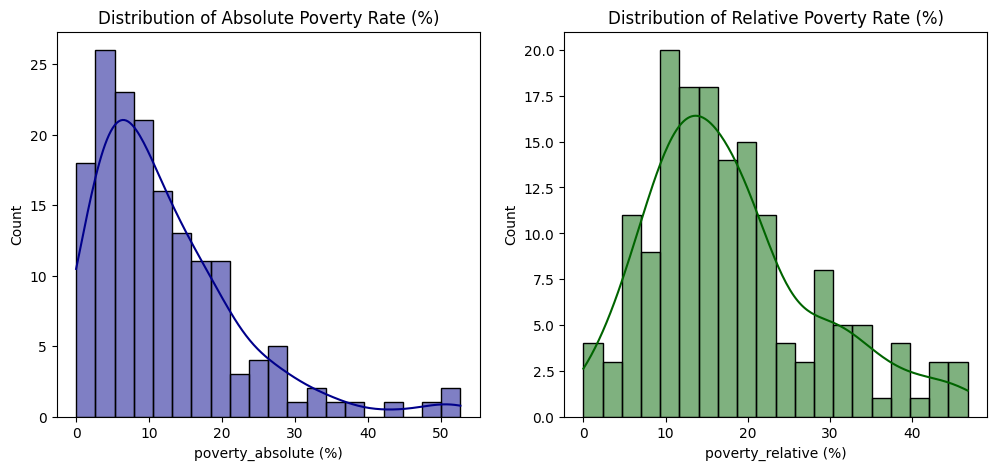

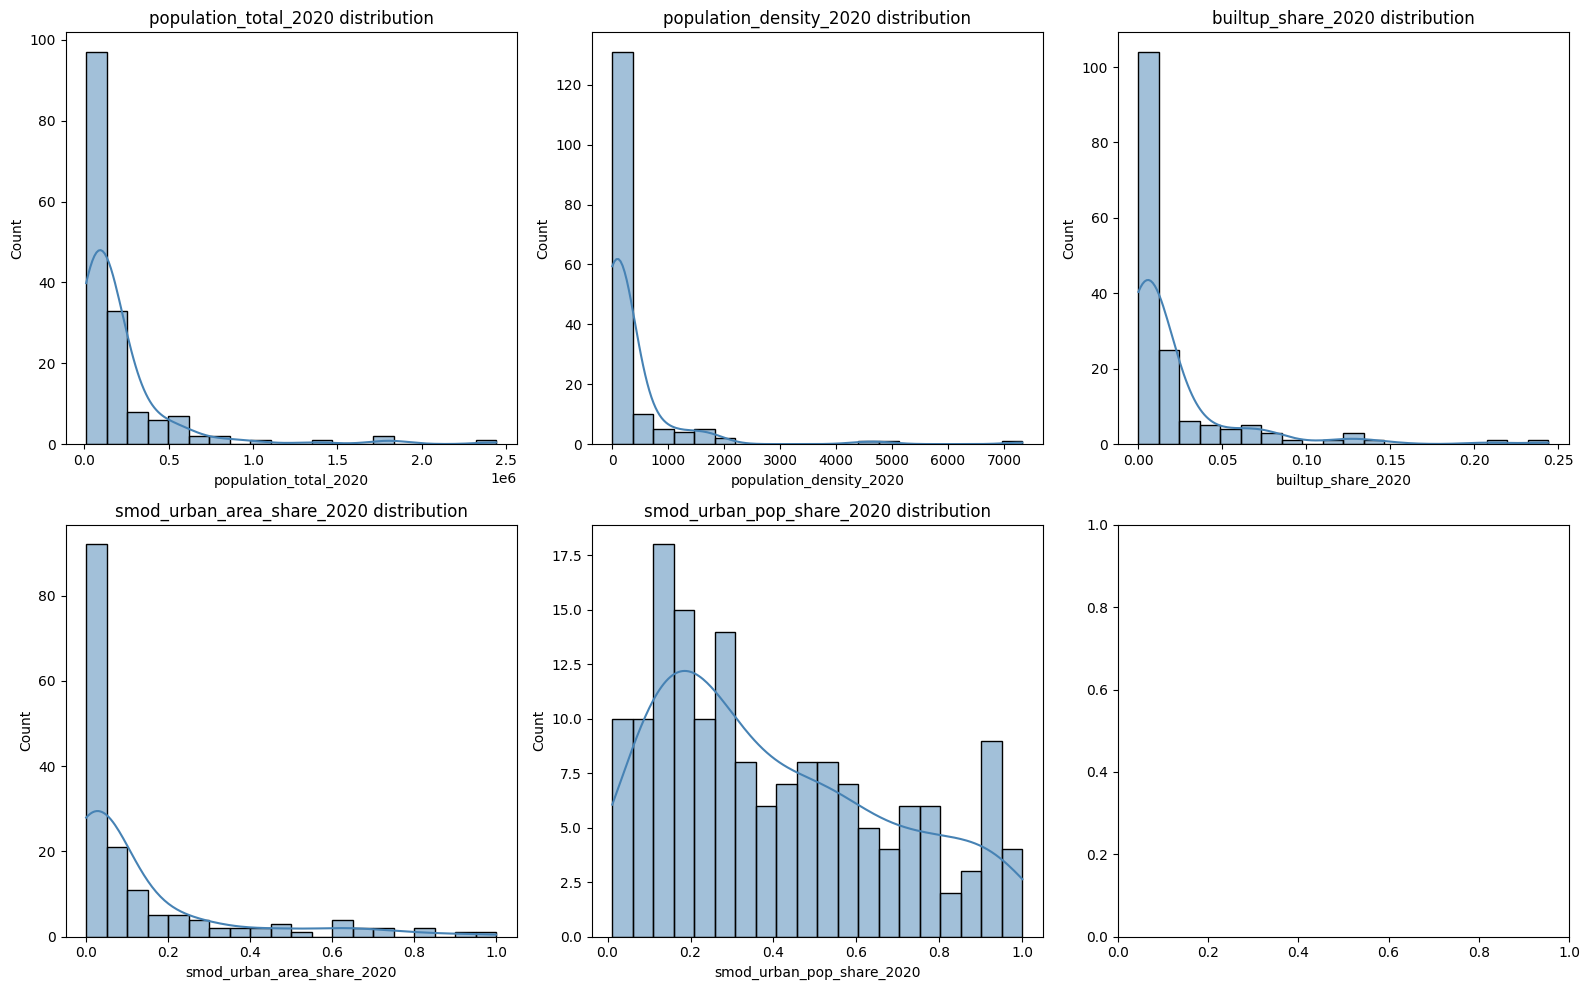

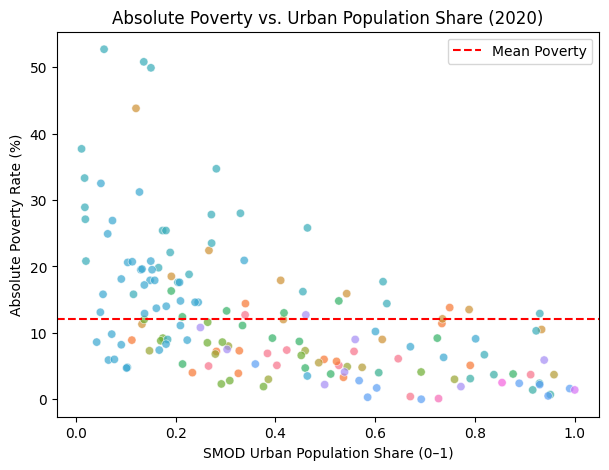

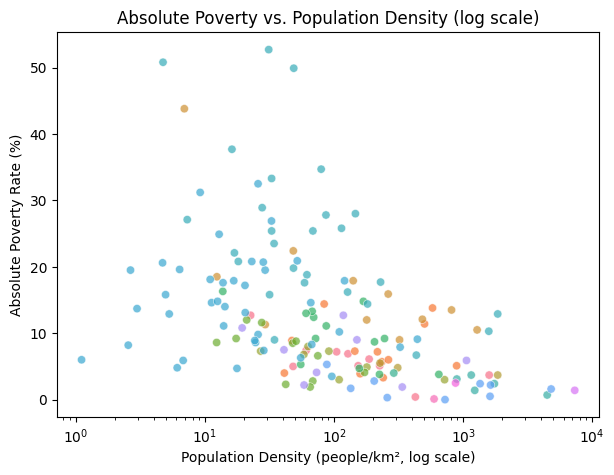

/tmp/ipython-input-2541526500.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_imputed, x="urban_quintile", y="poverty_absolute (%)", palette="Blues")


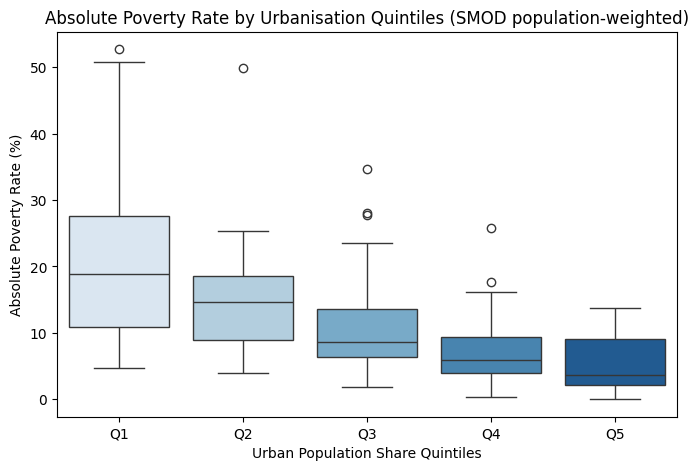

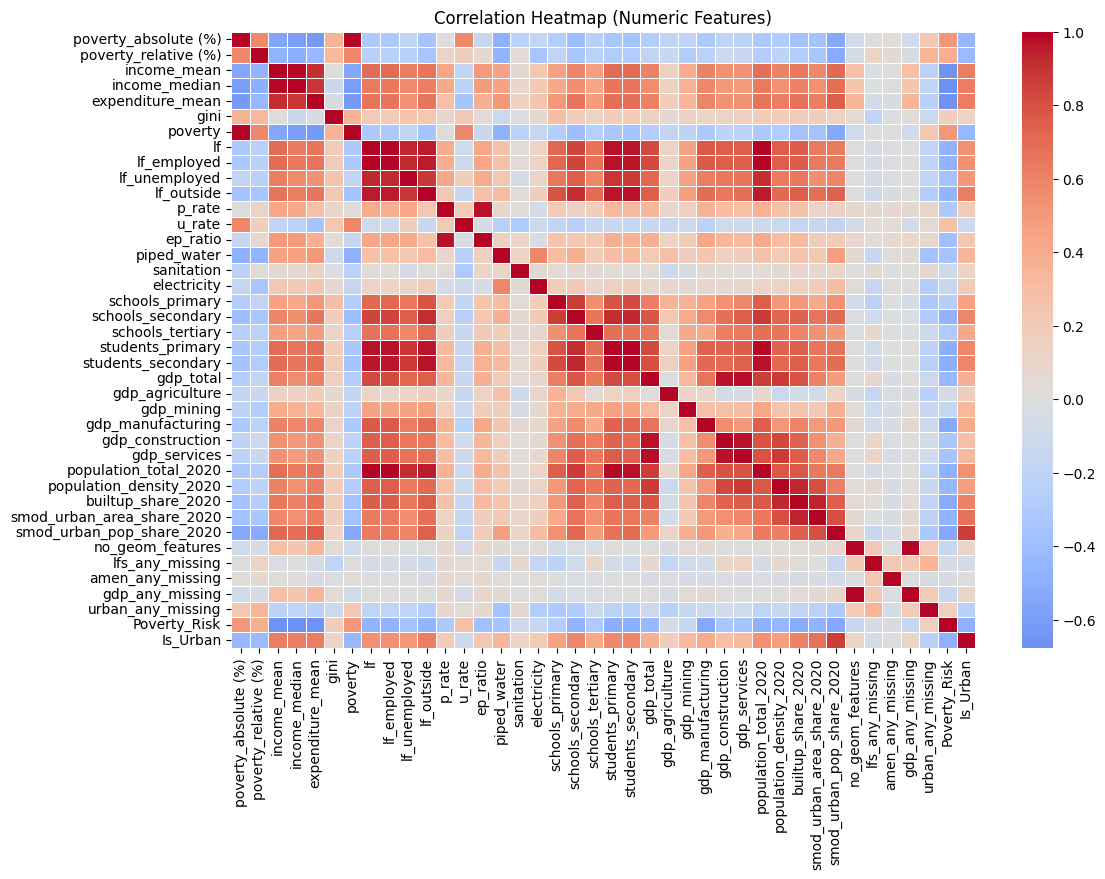


Top correlations with absolute poverty:
poverty_absolute (%)         1.000000
poverty                      1.000000
expenditure_mean            -0.621094
income_median               -0.600057
u_rate                       0.586833
poverty_relative (%)         0.575702
income_mean                 -0.557409
smod_urban_pop_share_2020   -0.541838
Poverty_Risk                 0.510190
piped_water                 -0.476552
Name: poverty_absolute (%), dtype: float64

State-level summary:
              state  poverty_absolute (%)  poverty_relative (%)  \
9             Sabah             24.929630             18.266667   
2          Kelantan             16.990909             16.900000   
10          Sarawak             14.500000             25.577500   
6             Perak              9.661538             16.230769   
1             Kedah              7.583333             11.425000   
5            Pahang              6.945455              8.281818   
12       Terengganu              6.762500    

/tmp/ipython-input-2541526500.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


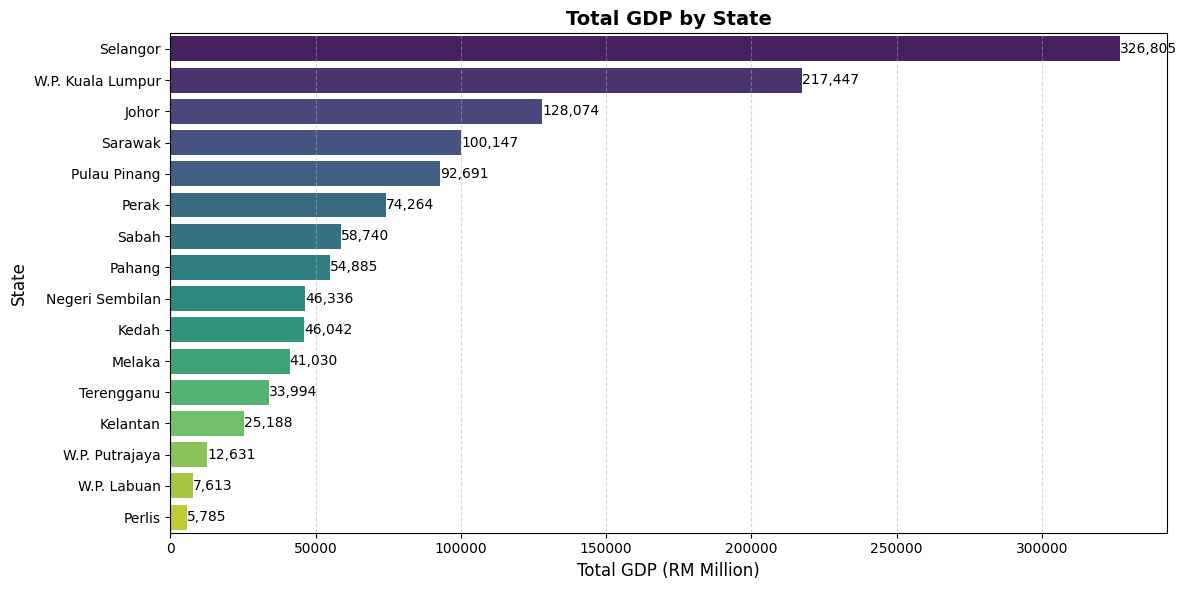

/tmp/ipython-input-2541526500.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


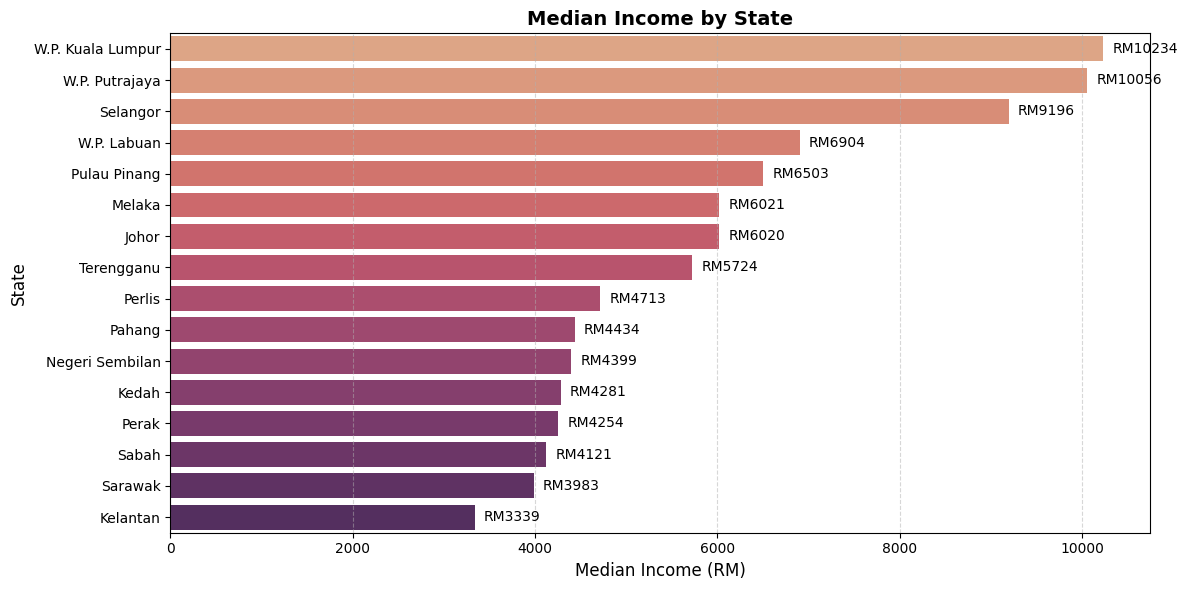

In [ ]:
# ======================================================
# EDA for Malaysian Urban Poverty Dataset (2022, District-level)
# Input: district_2022_transparent.csv
# Outputs: Plots + summary stats ready for report
# ======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load data ---
df_imputed = pd.read_csv("district_2022_imputed.csv")

# Quick overview
print("Shape:", df_imputed.shape)
print("Columns:", df_imputed.columns.tolist())
print(df_imputed.head())

# ======================================================
# 1. Target variable distributions (poverty)
# ======================================================
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.histplot(df_imputed["poverty_absolute (%)"], bins=20, kde=True, ax=axes[0], color="darkblue")
axes[0].set_title("Distribution of Absolute Poverty Rate (%)")
sns.histplot(df_imputed["poverty_relative (%)"], bins=20, kde=True, ax=axes[1], color="darkgreen")
axes[1].set_title("Distribution of Relative Poverty Rate (%)")
plt.show()

# ======================================================
# 2. Urbanisation features distributions
# ======================================================
urban_feats = [
    "population_total_2020",
    "population_density_2020",
    "builtup_share_2020",
    "smod_urban_area_share_2020",
    "smod_urban_pop_share_2020"
]

df_imputed[urban_feats].describe().T

fig, axes = plt.subplots(2, 3, figsize=(16,10))
axes = axes.flatten()
for i, col in enumerate(urban_feats):
    sns.histplot(df_imputed[col], bins=20, kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col} distribution")
plt.tight_layout()
plt.show()

# ======================================================
# 3. Poverty vs. Urbanisation (scatterplots)
# ======================================================
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_imputed, x="smod_urban_pop_share_2020", y="poverty_absolute (%)",
                hue="state", legend=False, alpha=0.7)
plt.title("Absolute Poverty vs. Urban Population Share (2020)")
plt.xlabel("SMOD Urban Population Share (0–1)")
plt.ylabel("Absolute Poverty Rate (%)")
plt.axhline(df_imputed["poverty_absolute (%)"].mean(), color="red", linestyle="--", label="Mean Poverty")
plt.legend()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(data=df_imputed, x="population_density_2020", y="poverty_absolute (%)",
                hue="state", legend=False, alpha=0.7)
plt.xscale("log")
plt.title("Absolute Poverty vs. Population Density (log scale)")
plt.xlabel("Population Density (people/km², log scale)")
plt.ylabel("Absolute Poverty Rate (%)")
plt.show()

# ======================================================
# 4. Boxplots by urbanisation quintiles
# ======================================================
df_imputed["urban_quintile"] = pd.qcut(df_imputed["smod_urban_pop_share_2020"], 5, labels=["Q1","Q2","Q3","Q4","Q5"])

plt.figure(figsize=(8,5))
sns.boxplot(data=df_imputed, x="urban_quintile", y="poverty_absolute (%)", palette="Blues")
plt.title("Absolute Poverty Rate by Urbanisation Quintiles (SMOD population-weighted)")
plt.xlabel("Urban Population Share Quintiles")
plt.ylabel("Absolute Poverty Rate (%)")
plt.show()

# ======================================================
# 5. Correlation heatmap (features vs poverty)
# ======================================================
# Select numeric features only
num_df = df_imputed.select_dtypes(include=[np.number]).copy()
corr = num_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()

# Focus: top correlations with absolute poverty
abs_corr = corr["poverty_absolute (%)"].dropna().sort_values(key=np.abs, ascending=False)
print("\nTop correlations with absolute poverty:")
print(abs_corr.head(10))

# ======================================================
# 6. State-level poverty vs urbanisation summary
# ======================================================
state_summary = df_imputed.groupby("state").agg({
    "poverty_absolute (%)":"mean",
    "poverty_relative (%)":"mean",
    "smod_urban_pop_share_2020":"mean",
    "population_density_2020":"mean"
}).reset_index().sort_values("poverty_absolute (%)", ascending=False)

print("\nState-level summary:")
print(state_summary.head(10))

# ======================================================
# 7. Total GDP by State
# ======================================================
state_gdp = df_imputed.groupby('state')['gdp_total'].sum().sort_values(ascending=False).reset_index()

# Create the Plot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=state_gdp,
    x='gdp_total',
    y='state',
    palette='viridis'
)

# Styling
plt.title("Total GDP by State", fontsize=14, fontweight='bold')
plt.xlabel("Total GDP (RM Million)", fontsize=12)
plt.ylabel("State", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add Value Labels
for index, row in state_gdp.iterrows():
    plt.text(
        x=row.gdp_total,
        y=index,
        s=f"{row.gdp_total:,.0f}",
        va='center',
        fontsize=10,
    )
plt.tight_layout()
plt.show()

# ======================================================
# 8. Median Income by State
# ======================================================
state_income = df_imputed.groupby('state')['income_median'].mean().sort_values(ascending=False).reset_index()

# Create the Plot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=state_income,
    x='income_median',
    y='state',
    palette='flare'
)

# Styling
plt.title("Median Income by State", fontsize=14, fontweight='bold')
plt.xlabel("Median Income (RM)", fontsize=12)
plt.ylabel("State", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Value Labels
for index, row in state_income.iterrows():
    plt.text(row.income_median + 100, index, f"RM{row.income_median:,.0f}", va='center', fontsize=10)

plt.tight_layout()
plt.show()

Saved: state_summary.csv


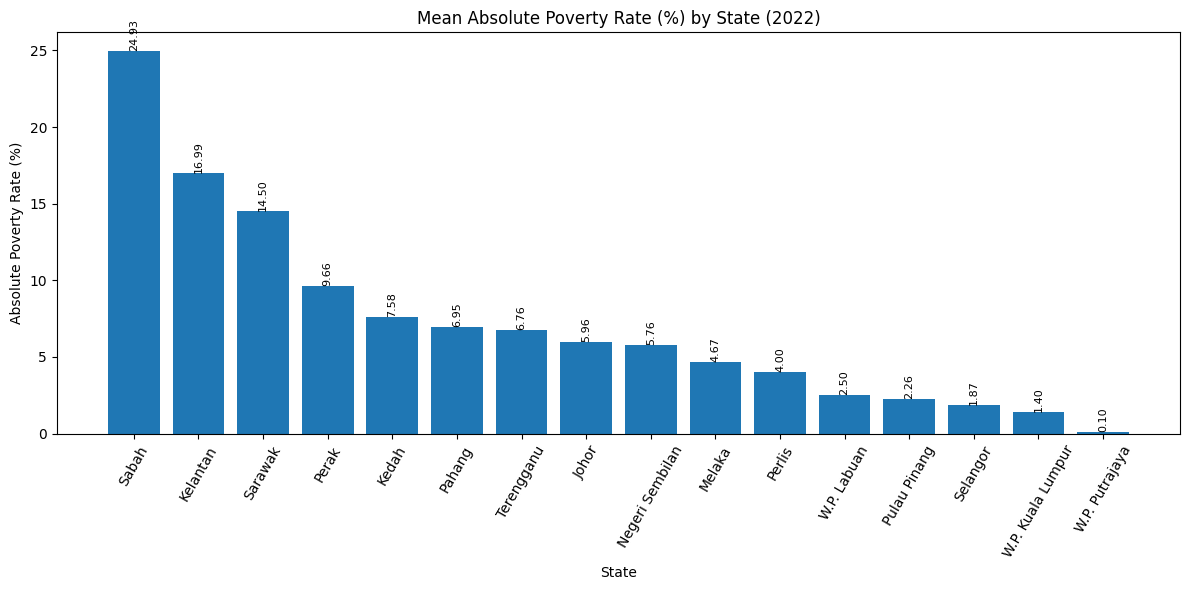

Saved: fig_state_abs_poverty.png


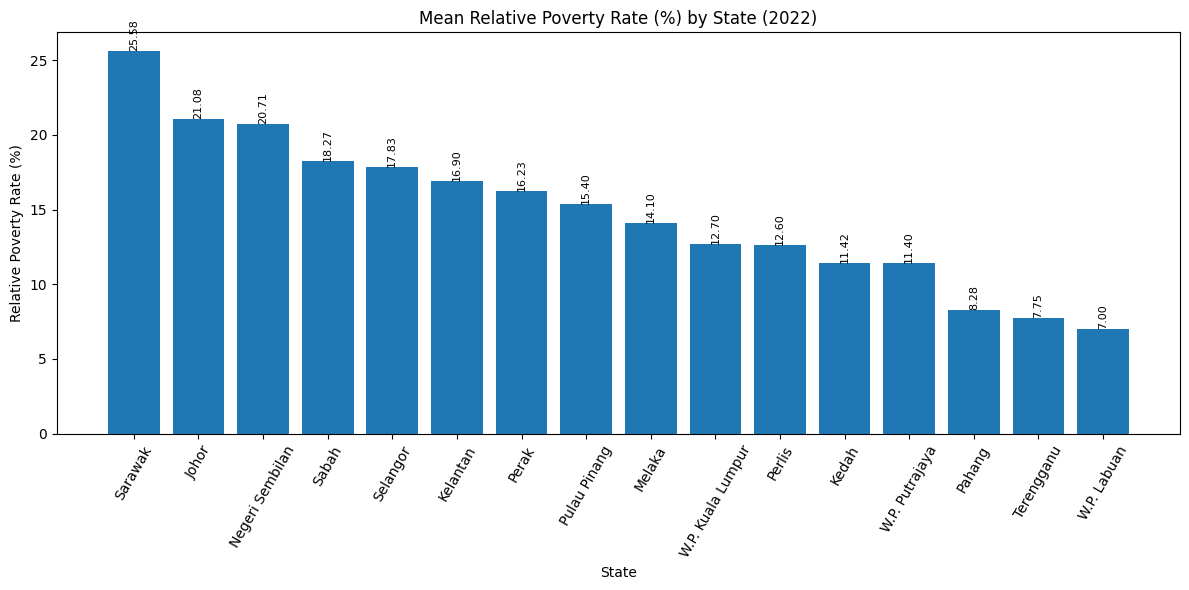

Saved: fig_state_rel_poverty.png


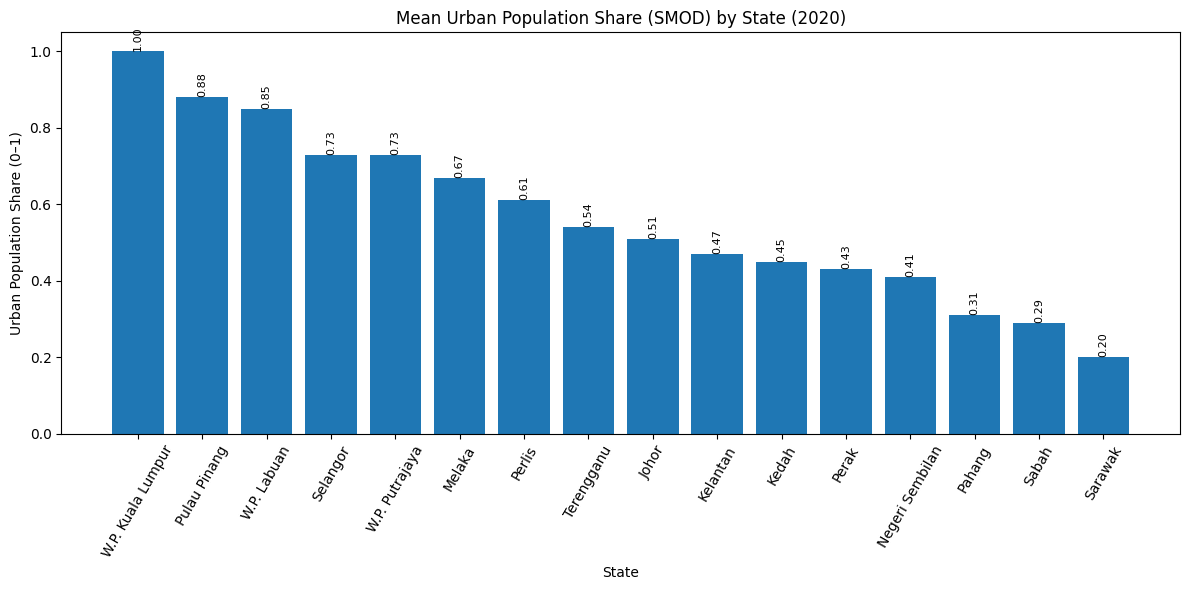

Saved: fig_state_urban_share.png


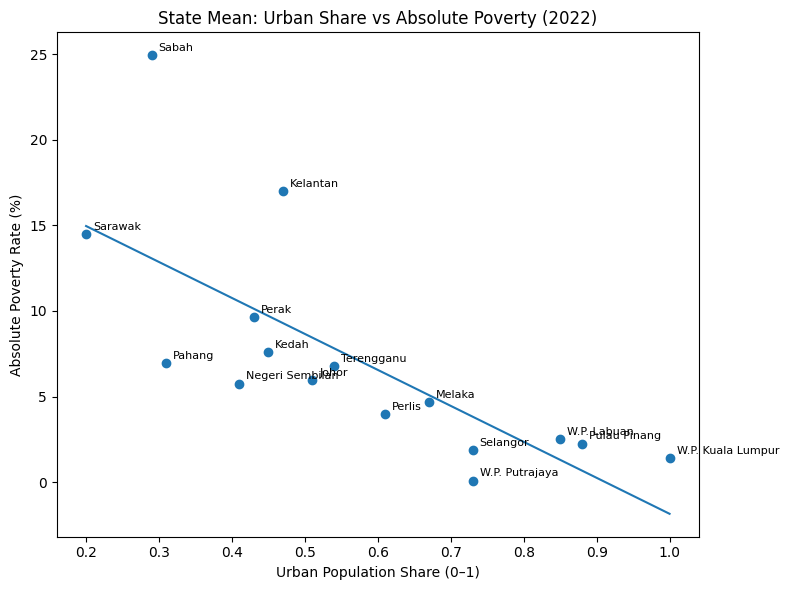

Saved: fig_state_urban_vs_poverty.png

Top 5 states by absolute poverty (%):
       state  poverty_absolute (%)  poverty_relative (%)  \
9      Sabah                 24.93                 18.27   
2   Kelantan                 16.99                 16.90   
10   Sarawak                 14.50                 25.58   
6      Perak                  9.66                 16.23   
1      Kedah                  7.58                 11.42   

    smod_urban_pop_share_2020  population_density_2020  
9                        0.29               200.347596  
2                        0.47               325.582993  
10                       0.20                44.836213  
6                        0.43               159.741884  
1                        0.45               283.695603  

Top 5 states by urban population share:
                state  poverty_absolute (%)  poverty_relative (%)  \
13  W.P. Kuala Lumpur                  1.40                 12.70   
8        Pulau Pinang                  2.

In [ ]:
# ============================================
# State-Level Comparisons (Graphs + Summary)
# Inputs: district_2022_imputed.csv
# Outputs: PNG figures + state_summary.csv
# Charts: pure matplotlib (no seaborn), one chart per figure
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- Config ----------
IN_PATH = Path("district_2022_imputed.csv")
OUT_DIR = IN_PATH.parent

# Columns expected
COL_STATE = "state"
COL_ABS_POV = "poverty_absolute (%)"
COL_REL_POV = "poverty_relative (%)"
COL_URBAN_SHARE = "smod_urban_pop_share_2020"
COL_DENS = "population_density_2020"

# ---------- Load ----------
df = pd.read_csv(IN_PATH)

# Basic checks
for col in [COL_STATE, COL_ABS_POV, COL_REL_POV, COL_URBAN_SHARE]:
    if col not in df.columns:
        raise ValueError(f"Missing expected column: {col}")

# ---------- Aggregate to state level ----------
state_summary = (
    df.groupby(COL_STATE, dropna=False)
      .agg({
          COL_ABS_POV: "mean",
          COL_REL_POV: "mean",
          COL_URBAN_SHARE: "mean",
          COL_DENS: "mean" if COL_DENS in df.columns else "mean"
      })
      .reset_index()
)

# Round for tidy labels
state_summary_rounded = state_summary.copy()
for c in [COL_ABS_POV, COL_REL_POV, COL_URBAN_SHARE]:
    if c in state_summary_rounded.columns:
        state_summary_rounded[c] = state_summary_rounded[c].round(2)

# Save summary table
summary_csv = OUT_DIR / "state_summary.csv"
state_summary_rounded.to_csv(summary_csv, index=False, encoding="utf-8-sig")
print(f"Saved: {summary_csv}")

# Helper: generic bar plot
def barplot_sorted(df_in, x_col, y_col, title, ylabel, fname):
    df_plot = df_in[[x_col, y_col]].dropna().sort_values(y_col, ascending=False)
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(111)
    ax.bar(df_plot[x_col], df_plot[y_col])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("State")
    ax.tick_params(axis='x', rotation=60)
    # annotate bars with value
    for i, v in enumerate(df_plot[y_col].values):
        ax.text(i, v, f"{v:.2f}", ha='center', va='bottom', fontsize=8, rotation=90)
    fig.tight_layout()
    out = OUT_DIR / fname
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")

# ---------- Figure 1: Absolute poverty by state ----------
barplot_sorted(
    state_summary_rounded,
    COL_STATE,
    COL_ABS_POV,
    "Mean Absolute Poverty Rate (%) by State (2022)",
    "Absolute Poverty Rate (%)",
    "fig_state_abs_poverty.png"
)

# ---------- Figure 2: Relative poverty by state ----------
barplot_sorted(
    state_summary_rounded,
    COL_STATE,
    COL_REL_POV,
    "Mean Relative Poverty Rate (%) by State (2022)",
    "Relative Poverty Rate (%)",
    "fig_state_rel_poverty.png"
)

# ---------- Figure 3: Urban population share (SMOD) by state ----------
barplot_sorted(
    state_summary_rounded,
    COL_STATE,
    COL_URBAN_SHARE,
    "Mean Urban Population Share (SMOD) by State (2020)",
    "Urban Population Share (0–1)",
    "fig_state_urban_share.png"
)

# ---------- Figure 4: Urban share vs Absolute Poverty (scatter) ----------
# One chart, no subplots; label each point with state name
df_scatter = state_summary_rounded[[COL_STATE, COL_URBAN_SHARE, COL_ABS_POV]].dropna()
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
ax.scatter(df_scatter[COL_URBAN_SHARE], df_scatter[COL_ABS_POV])
ax.set_title("State Mean: Urban Share vs Absolute Poverty (2022)")
ax.set_xlabel("Urban Population Share (0–1)")
ax.set_ylabel("Absolute Poverty Rate (%)")

# Add simple least-squares trendline
x = df_scatter[COL_URBAN_SHARE].values
y = df_scatter[COL_ABS_POV].values
if len(x) >= 2 and np.isfinite(x).all() and np.isfinite(y).all():
    m, b = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = m * x_line + b
    ax.plot(x_line, y_line)

# Label points
for _, row in df_scatter.iterrows():
    ax.annotate(row[COL_STATE], (row[COL_URBAN_SHARE], row[COL_ABS_POV]),
                textcoords="offset points", xytext=(5, 3), fontsize=8)

fig.tight_layout()
out = OUT_DIR / "fig_state_urban_vs_poverty.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

# ----------  Console preview ----------
print("\nTop 5 states by absolute poverty (%):")
print(state_summary_rounded.sort_values(COL_ABS_POV, ascending=False).head(5))

print("\nTop 5 states by urban population share:")
print(state_summary_rounded.sort_values(COL_URBAN_SHARE, ascending=False).head(5))

# **Modeling**

In [ ]:
# =========================================================
# STEP 0: INSTALL LIBRARIES
# =========================================================
import subprocess
import sys

def install(package):
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

install("sdv")
install("xgboost")

# =========================================================
# STEP 1: IMPORT & LOAD
# =========================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, precision_score, classification_report

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb

# GenAI
from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer

# Load Data
df = pd.read_csv("district_2022_imputed.csv")

# --- DATA PREPARATION ---
# 1. Remove unnecessarry columns
# We keep 'Is_Urban' because it is a valid feature for prediction
drop_cols = ['poverty', 'poverty_absolute (%)', 'poverty_relative (%)', 'date_2022', 'district']
df_final = df.drop(columns=[c for c in drop_cols if c in df.columns], errors='ignore')

# 2. Split Features (X) and Target (y)
X = df_final.drop(columns=['Poverty_Risk'])
y = df_final['Poverty_Risk']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# =========================================================
# STEP 2: RUN GEN-AI (CTGAN) ON RAW DATA
# =========================================================
print("\n--- 1. INNOVATION: Training GenAI (CTGAN) ---")
import torch
import random

# --- CRITICAL FIX: FREEZE THE GEN-AI RANDOMNESS ---
def set_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seeds(42)

# Setup Data for GenAI
train_data_raw = X_train.copy()
train_data_raw['Poverty_Risk'] = y_train.values

# Detect Metadata
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(train_data_raw)

# CRITICAL: Force 'state' to be categorical
if 'state' in train_data_raw.columns:
    metadata.update_column(column_name='state', sdtype='categorical')

# Train Synthesizer
synthesizer = CTGANSynthesizer(metadata, epochs=200, verbose=False)
synthesizer.fit(train_data_raw)

# Generate 800 Synthetic Samples
synthetic_data = synthesizer.sample(num_rows=800)
augmented_train_df = pd.concat([train_data_raw, synthetic_data], ignore_index=True)

# Separate Augmented X and y
X_train_aug = augmented_train_df.drop(columns=['Poverty_Risk'])
y_train_aug = augmented_train_df['Poverty_Risk']

print(f"GenAI Complete! Training set increased from {len(X_train)} to {len(augmented_train_df)} rows.")

# =========================================
# STEP 3: PREPROCESSING (Standardization Only)
# =========================================================
categorical_cols = ['state']
numerical_cols = [c for c in X.columns if c not in categorical_cols]

# Preprocessing Pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

# Fit on Augmented Data, Transform Both
X_train_final = preprocessor.fit_transform(X_train_aug)
X_test_final = preprocessor.transform(X_test)

# Prepare Urban Test Set for later (Using X_test directly)
# We need to identify which rows in the TEST set are Urban
if 'Is_Urban' in X_test.columns:
    urban_mask = X_test['Is_Urban'] == 1
    X_test_urban = X_test_final[urban_mask.values]
    y_test_urban = y_test[urban_mask]
else:
    print("Warning: 'Is_Urban' column not found. Skipping specific urban split.")
    X_test_urban = X_test_final
    y_test_urban = y_test

# =========================================================
# STEP 4: MULTI-MODEL BENCHMARKING
# =========================================================
print("\n--- 2. BENCHMARKING: Training 4 Models ---")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "XGBoost": xgb.XGBClassifier(eval_metric='logloss', use_label_encoder=False, random_state=42)
}

results = {}
best_model = None
best_score = 0
best_name = ""

print(f"{'Model':<20} | {'Accuracy':<10} | {'Recall' :<10} | {'Precision' :<10} | {'F1-Score':<10} | {'ROC AUC' :<10}|")
print("-" * 55)

for name, model in models.items():
    model.fit(X_train_final, y_train_aug)
    y_pred = model.predict(X_test_final)

    if hasattr(model, "predict_proba"):
        y_probs = model.predict_proba(X_test_final)[:, 1]
        auc = roc_auc_score(y_test, y_probs)
    else:
        auc = roc_auc_score(y_test, y_pred)

    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results[name] = model
    print(f"{name:<20} | {acc:.2%}     | {rec:.2%}     | {prec:.2%}     | {f1:.2%}     | {auc:.4f}     |")

    if acc > best_score:
        best_score = acc
        best_model = model
        best_name = name
print(f"\n🏆 WINNER: {best_name} (Accuracy: {best_score:.2%})")

# =========================================================
# STEP 5: DEEP DIVE - URBAN POVERTY ANALYSIS
# =========================================================
print(f"\n--- 3. RESEARCH FINDING: Urban Poverty ({best_name}) ---")

# Predict on Urban Districts only using the Winner
# Tuning Threshold to 0.5 to catch hidden poverty
if 'Is_Urban' in X_test.columns:
    y_probs = best_model.predict_proba(X_test_urban)[:, 1]
    y_pred_urban = (y_probs >= 0.5).astype(int)

    print("Classification Report (Urban Districts Only):")
    print(classification_report(y_test_urban, y_pred_urban))

    recall_urban = recall_score(y_test_urban, y_pred_urban)
    print(f"Conclusion: By using GenAI augmentation and the {best_name} algorithm,")
    print(f"we successfully identified {recall_urban:.0%} of high-risk urban districts.")
else:
    print("Skipping Urban Analysis as 'Is_Urban' column was not found.")


--- 1. INNOVATION: Training GenAI (CTGAN) ---


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:168: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


GenAI Complete! Training set increased from 128 to 928 rows.

--- 2. BENCHMARKING: Training 4 Models ---
Model                | Accuracy   | Recall     | Precision  | F1-Score   | ROC AUC   |
-------------------------------------------------------
Logistic Regression  | 84.38%     | 96.00%     | 85.71%     | 90.57%     | 0.8229     |
Random Forest        | 90.62%     | 100.00%     | 89.29%     | 94.34%     | 0.9029     |
SVM                  | 81.25%     | 100.00%     | 80.65%     | 89.29%     | 0.8571     |


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [15:11:43] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost              | 84.38%     | 88.00%     | 91.67%     | 89.80%     | 0.8229     |

🏆 WINNER: Random Forest (Accuracy: 90.62%)

--- 3. RESEARCH FINDING: Urban Poverty (Random Forest) ---
Classification Report (Urban Districts Only):
              precision    recall  f1-score   support

           0       1.00      0.20      0.33         5
           1       0.50      1.00      0.67         4

    accuracy                           0.56         9
   macro avg       0.75      0.60      0.50         9
weighted avg       0.78      0.56      0.48         9

Conclusion: By using GenAI augmentation and the Random Forest algorithm,
we successfully identified 100% of high-risk urban districts.


In [ ]:
print(f"\n--- 3. RESEARCH FINDING: Urban Poverty ({best_name}) ---")

# TEST: Tuning Threshold to 0.5 to catch hidden poverty
if 'Is_Urban' in X_test.columns:
    y_probs = best_model.predict_proba(X_test_urban)[:, 1]
    y_pred_urban = (y_probs >= 0.5).astype(int)

    print("Classification Report (Urban Districts Only):")
    print(classification_report(y_test_urban, y_pred_urban))

    recall_urban = recall_score(y_test_urban, y_pred_urban)
    print(f"Conclusion: By using GenAI augmentation and the {best_name} algorithm,")
    print(f"we successfully identified {recall_urban:.0%} of high-risk urban districts.")
else:
    print("Skipping Urban Analysis as 'Is_Urban' column was not found.")


--- 3. RESEARCH FINDING: Urban Poverty (Random Forest) ---
Classification Report (Urban Districts Only):
              precision    recall  f1-score   support

           0       1.00      0.80      0.89         5
           1       0.80      1.00      0.89         4

    accuracy                           0.89         9
   macro avg       0.90      0.90      0.89         9
weighted avg       0.91      0.89      0.89         9

Conclusion: By using GenAI augmentation and the Random Forest algorithm,
we successfully identified 100% of high-risk urban districts.


In [ ]:
print(f"\n--- 3. RESEARCH FINDING: Urban Poverty ({best_name}) ---")

# TEST: Tuning Threshold to 0.6 to catch hidden poverty
if 'Is_Urban' in X_test.columns:
    y_probs = best_model.predict_proba(X_test_urban)[:, 1]
    y_pred_urban = (y_probs >= 0.6).astype(int)

    print("Classification Report (Urban Districts Only):")
    print(classification_report(y_test_urban, y_pred_urban))

    recall_urban = recall_score(y_test_urban, y_pred_urban)
    print(f"Conclusion: By using GenAI augmentation and the {best_name} algorithm,")
    print(f"we successfully identified {recall_urban:.0%} of high-risk urban districts.")
else:
    print("Skipping Urban Analysis as 'Is_Urban' column was not found.")


--- 3. RESEARCH FINDING: Urban Poverty (Random Forest) ---
Classification Report (Urban Districts Only):
              precision    recall  f1-score   support

           0       0.67      0.80      0.73         5
           1       0.67      0.50      0.57         4

    accuracy                           0.67         9
   macro avg       0.67      0.65      0.65         9
weighted avg       0.67      0.67      0.66         9

Conclusion: By using GenAI augmentation and the Random Forest algorithm,
we successfully identified 50% of high-risk urban districts.


Among three threshold (0.35, 0.5, 0.6), 0.5 generated the best result, so we will apply 0.5.

# **Deployment**

In [ ]:
# --- 1. SETUP & INSTALLATION ---
# Install Streamlit, Tunneling, Geospatial tools, CTGAN, XGBoost, SHAP
!pip install streamlit -q
!pip install pyngrok -q
!pip install geopandas rasterio rasterstats -q
!pip install ctgan -q
!pip install xgboost -q
!pip install protobuf==3.20.3
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 106.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.4/74.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 8.7 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled protobuf-5.29.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 3.20.3 which is incompatible.
ydf 0.13.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 3.20.3 which is incompatible.
tensorflow-metadata 1.17.2 requires protobuf>=4.25.2; python_versio

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier # <--- UPDATED IMPORT
from ctgan import CTGAN
import os

# --- PAGE CONFIGURATION ---
st.set_page_config(page_title="Poverty Risk AI System", layout="wide")

# --- DATA PROCESSING ENGINE (Cached) ---
@st.cache_data
def load_and_process_data():
    # 1. LOAD DATA
    file_path = "district_2022_transparent_clean.csv"
    df = pd.read_csv(file_path)

    # 2. KNN IMPUTATION (UNIVERSAL FIX)
    cols_to_impute = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

    if cols_to_impute:
        # A. Scale Temporarily
        scaler = StandardScaler()
        df_scaled = pd.DataFrame(scaler.fit_transform(df[cols_to_impute]), columns=cols_to_impute)

        # B. Impute Missing Values
        imputer = KNNImputer(n_neighbors=5)
        df_imputed_scaled = pd.DataFrame(imputer.fit_transform(df_scaled), columns=cols_to_impute)

        # C. Inverse Transform (Back to Real Numbers)
        df[cols_to_impute] = scaler.inverse_transform(df_imputed_scaled)

    # 3. FEATURE ENGINEERING
    if 'poverty_absolute (%)' in df.columns:
        df['Poverty_Risk'] = (df['poverty_absolute (%)'] > 4.7).astype(int)
    if 'smod_urban_pop_share_2020' in df.columns:
        df['Is_Urban'] = (df['smod_urban_pop_share_2020'] > 0.5).astype(int)

    return df

# --- MAIN DASHBOARD LOGIC ---
df = load_and_process_data()

if df is None:
    st.error("❌ Dataset not found. Please upload 'district_2022_transparent_clean.csv'.")
else:
    st.title("District Poverty Risk AI System")

    # --- GLOBAL SIDEBAR FILTER ---
    st.sidebar.header("Filter Options")

    # 1. State Filter
    if 'state' in df.columns:
        state_list = ["All"] + list(sorted(df['state'].unique()))
        selected_state = st.sidebar.selectbox("1. Select State", state_list)
    else:
        selected_state = "All"

    # 2. Urban/Rural Filter
    urban_mapping = {"All": "All", "Urban Only": 1, "Rural Only": 0}
    selected_type = st.sidebar.radio("2. District Type", list(urban_mapping.keys()))

    # --- APPLY FILTERS ---
    df_view = df.copy()

    if selected_state != "All":
        df_view = df_view[df_view['state'] == selected_state]

    if selected_type != "All":
        val = urban_mapping[selected_type]
        if 'Is_Urban' in df_view.columns:
            df_view = df_view[df_view['Is_Urban'] == val]

    # --- TABS ---
    tab1, tab2, tab3 = st.tabs(["📊 Data Profile", "📈 EDA Analysis", "🔮 AI Prediction"])

    # --- TAB 1: DATA PROFILE ---
    with tab1:
        st.header(f"Profile: {selected_state}")
        c1, c2, c3 = st.columns(3)
        c1.metric("Districts", len(df_view))
        c2.metric("Avg Income", f"RM {df_view['income_mean'].mean():.0f}")
        c3.metric("Avg Abs Poverty Rate", f"{df_view['poverty_absolute (%)'].mean():.2f}%")
        st.dataframe(df_view)

    # --- TAB 2: EDA ---
    with tab2:
        st.header(f"Exploratory Analysis ({selected_state})")
        if len(df_view) < 2:
            st.warning("⚠️ Not enough data to plot charts.")
        else:
            col1, col2 = st.columns(2)
            with col1:
                st.subheader("Mean Income Distribution by Risk Level")
                if df_view['Poverty_Risk'].nunique() > 0:
                    fig, ax = plt.subplots()
                    sns.boxplot(data=df_view, x='Poverty_Risk', y='income_mean', ax=ax, palette="Set2")
                    st.pyplot(fig)
            with col2:
                st.subheader("Poverty Risk Distribution by District Type")
                fig, ax = plt.subplots()
                sns.countplot(data=df_view, x='Is_Urban', hue='Poverty_Risk', ax=ax, palette="coolwarm")
                st.pyplot(fig)



    # --- TAB 3: AI PREDICTION (RANDOM FOREST + 0.5 THRESHOLD) ---
    with tab3:
        st.header(f"🔮 High-Risk Detection Model ({selected_state})")
        st.write("This model uses **Random Forest** (the study's top-performing model) with a **0.5 sensitivity threshold** to detect hidden poverty.")

        # =========================================================
        # 1. SESSION STATE SETUP
        # =========================================================
        if 'prediction_run' not in st.session_state:
            st.session_state.prediction_run = False

        if st.button("Run Prediction System"):
            st.session_state.prediction_run = True

        # =========================================================
        # 2. EXECUTE LOGIC BASED ON STATE
        # =========================================================
        if st.session_state.prediction_run:
            with st.spinner("Training Random Forest Model..."):
                try:
                    # 1. DEFINE COLUMNS TO DROP
                    drop_cols = ['Poverty_Risk', 'poverty_absolute (%)', 'poverty_relative (%)', 'poverty',
                                 'date_2022', 'district', 'state']

                    # 2. PREPARE TRAINING DATA (National)
                    X_train = df.drop(columns=[c for c in drop_cols if c in df.columns], errors='ignore')
                    y_train = df['Poverty_Risk']
                    X_train_encoded = pd.get_dummies(X_train, drop_first=True)

                    # 3. TRAIN MODEL (Random Forest)
                    model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
                    model.fit(X_train_encoded, y_train)

                    # 4. PREDICT ON SELECTED STATE
                    X_target = df_view.drop(columns=[c for c in drop_cols if c in df_view.columns], errors='ignore')
                    X_target_encoded = pd.get_dummies(X_target, drop_first=True)
                    # Align columns
                    X_target_encoded = X_target_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

                    # 5. GET PROBABILITIES & APPLY 0.5 THRESHOLD
                    probs = model.predict_proba(X_target_encoded)[:, 1]
                    custom_preds = (probs >= 0.5).astype(int)

                    # 6. FEATURE IMPORTANCE (Random Forest)
                    imp_df = pd.DataFrame({
                        'Feature': X_train_encoded.columns,
                        'Importance': model.feature_importances_
                    }).sort_values('Importance', ascending=False).head(10)

                    st.subheader("📊 National Feature Importance (Random Forest)")
                    fig_imp, ax_imp = plt.subplots(figsize=(10, 5))

                    # Create the plot
                    sns.barplot(data=imp_df, x='Importance', y='Feature', ax=ax_imp, palette="viridis")

                    for container in ax_imp.containers:
                        ax_imp.bar_label(container, fmt='%.2f', padding=3)

                    ax_imp.set_title("Most Influential Factors in Predicting Poverty Risk")
                    ax_imp.set_xlabel("Importance Score")
                    st.pyplot(fig_imp)
                    st.caption("Longer bars indicate factors that the AI relies on most to make decisions.")

                    st.divider()

                    # 7. RESULTS TABLE
                    results_table = pd.DataFrame({
                        'District': df_view['district'],
                        'State': df_view['state'],
                        'Actual_Poverty_Rate': df_view['poverty_absolute (%)'],
                        'AI_Prediction': ['High Risk' if p==1 else 'Low Risk' for p in custom_preds],
                        'Risk_Probability': probs
                    })

                    st.subheader(f"⚠️ Risk Analysis for {selected_state}")
                    high_risk = results_table[results_table['AI_Prediction'] == 'High Risk'].sort_values('Risk_Probability', ascending=False)

                    if high_risk.empty:
                        st.success(f"✅ No High Risk districts detected in {selected_state} (at >50% confidence).")
                    else:
                        st.write("Districts flagged as **High Risk** (Confidence > 50%):")
                        st.dataframe(
                            high_risk.style.format({'Actual_Poverty_Rate': "{:.1f}%", 'Risk_Probability': "{:.1%}"})
                            .background_gradient(subset=['Risk_Probability'], cmap='Reds')
                        )

                    st.divider()

                    # 8. SHAP WATERFALL
                    st.subheader("🔍 District Risk Diagnostics: What Increases or Decreases Risk?")

                    import shap

                    # A. Selector: Choose a district from the current view
                    shap_district = st.selectbox("Select a district to explain:", df_view['district'].unique(), key='shap_select')

                    # B. Get Data for selected district
                    selected_row_index = df_view[df_view['district'] == shap_district].index[0]

                    # Extract and encode
                    row_raw = df_view.loc[[selected_row_index]].drop(columns=[c for c in drop_cols if c in df_view.columns], errors='ignore')
                    row_encoded = pd.get_dummies(row_raw, drop_first=True)
                    row_encoded = row_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

                    # C. Calculate SHAP Values
                    explainer = shap.TreeExplainer(model)
                    shap_values = explainer.shap_values(row_encoded)

                    # D. Handle Output
                    if isinstance(shap_values, list):
                        shap_val_plot = shap_values[1][0]
                        base_val_plot = explainer.expected_value[1]
                    elif len(shap_values.shape) == 3:
                        shap_val_plot = shap_values[0, :, 1]
                        base_val_plot = explainer.expected_value[1]
                    else:
                        shap_val_plot = shap_values[0]
                        base_val_plot = explainer.expected_value

                    # E. Plot the Waterfall
                    st.write(f"**Risk Factor Breakdown for {shap_district}:**")
                    fig_shap = plt.figure(figsize=(8, 6))

                    exp = shap.Explanation(
                        values=shap_val_plot,
                        base_values=base_val_plot,
                        data=row_encoded.iloc[0].values,
                        feature_names=row_encoded.columns
                    )

                    shap.plots.waterfall(exp, show=False)
                    st.pyplot(fig_shap)

                    st.info("""
                    **Chart Guide:**
                    * 🟥 **Red Bars:** Bad factors INCREASING poverty risk.
                    * 🟦 **Blue Bars:** Good factors DECREASING poverty risk.
                    """)

                except Exception as e:
                    st.error(f"Prediction Error: {e}")

Overwriting app.py


In [ ]:
# --- 3. LAUNCH DEPLOYMENT ---
from pyngrok import ngrok, conf

auth_token = "37uKWQohFg8ZddY1rh7eairlSTs_4TM2ZzAZJStMGAuJ1S8Ve"
# ------------------------------

# Set the token
conf.get_default().auth_token = auth_token

!streamlit run app.py &>/dev/null&

import time

# Wait for app to start
time.sleep(3)

# Kill old tunnels
tunnels = ngrok.get_tunnels()
for tunnel in tunnels:
    ngrok.disconnect(tunnel.public_url)

# Open new tunnel
public_url = ngrok.connect(8501)
print(f"🚀 Application Live at: {public_url}")

🚀 Application Live at: NgrokTunnel: "https://lucina-uncontrived-overluxuriantly.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!pip install nbconvert
!jupyter nbconvert --to html Python_Research_Project.ipynb

[NbConvertApp] Converting notebook Python_Research_Project.ipynb to html
/usr/local/share/jupyter/nbconvert/templates/base/display_priority.j2:32: UserWarning: Your element with mimetype(s) dict_keys(['application/vnd.colab-display-data+json']) is not able to be represented.
  {%- elif type == 'text/vnd.mermaid' -%}
[NbConvertApp] WARNING | Alternative text is missing on 12 image(s).
[NbConvertApp] Writing 1811984 bytes to Python_Research_Project.html
